# Análisis exploratorio para el pronóstico de la demanda

Los cuadernos `ausgrid_exploration.ipynb` y `weather_exploration.ipynb` revisaron la calidad de los datos. Este cuaderno tiene otro objetivo: describir los patrones de la demanda que condicionan cómo se construyen y se evalúan los modelos de pronóstico. Se trabaja con `data/processed/ausgrid_era5_joined.parquet`, y la variable estudiada es `demand_kwh`, el consumo total de cada hogar en cada hora.

Esta primera parte cubre seis bloques:

- **0. Preparación**: partición de los datos, hora local y calendario.
- **1. Distribución de la variable objetivo**: forma, valores bajos, picos y relación entre la media y la mediana.
- **2. Diferencias entre hogares**: nivel, variabilidad, forma del perfil diario y periodos atípicos.
- **3. Estacionalidades y calendario**: día de la semana, festivos y Navidad, época del año y hora local.
- **4. Dependencia temporal**: autocorrelación, persistencia, duración de las desviaciones, horizontes de semanas y meses y regularidad de la carga controlada.
- **5. Relación con el clima**: temperatura, lo que añade al calendario, horas del día, diferencias entre hogares y humedad y otras variables.

Aquí solo se describen los datos. Las decisiones de modelado (métricas, transformaciones, función de pérdida, tipo de modelo) se tomarán más adelante. Al final del cuaderno se recogen los hallazgos y las preguntas que dejan abiertas.

Cuando el texto habla del **Plan** se refiere a `Plan.md`, en la raíz del repositorio, que recoge los modelos que se van a implementar (las referencias de persistencia, LightGBM, LSTM, TFT y Chronos-2), las variables que usarán y las métricas con las que se evaluarán. Varias secciones comprueban si los datos apoyan lo que allí se prevé.

## 0. Preparación

### 0.1 Partición: el año de test no se analiza

El último año, 2012-2013, se reserva para evaluar los modelos y no se usa en este análisis. Si se mirara, las decisiones sobre variables y modelos se tomarían con información del mismo periodo con el que después se mide el error, y la evaluación saldría más optimista de lo que es. Todo el cuaderno trabaja con 2010-2011 y 2011-2012.

In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
data_path = project_root / "data" / "processed" / "ausgrid_era5_joined.parquet"
if not data_path.is_file():
    raise FileNotFoundError(f"No se encontró {data_path}. Ejecutar antes los scripts de src/preprocessing.")

LOCAL_TZ = "Australia/Sydney"
TRAIN_PERIODS = ["2010-2011", "2011-2012"]
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)

# Estilo de los gráficos
SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3de"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
YELLOW = "#eda100"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 100,
    "font.size": 9.5,
    "text.color": TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 10.5,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})

In [2]:
columns = ["customer", "timestamp_utc", "source_period", "generator_capacity_kwp",
           "gc_kwh", "cl_kwh", "demand_kwh", "has_cl", "cl_estimated"]
data = pd.read_parquet(data_path, columns=columns)

split = data.groupby("source_period", observed=True).agg(
    filas=("customer", "size"),
    hogares=("customer", "nunique"),
    filas_cl_estimado=("cl_estimated", "sum"),
)
split["uso"] = ["análisis y entrenamiento", "análisis y entrenamiento", "test: no se analiza"]
display(split)

train = data.loc[data["source_period"].isin(TRAIN_PERIODS)].reset_index(drop=True)
del data
if train["cl_estimated"].any():
    raise ValueError("Hay CL estimado en los años de entrenamiento")
train = train.drop(columns="cl_estimated")
train["source_period"] = train["source_period"].cat.remove_unused_categories()

hours_per_customer = train.groupby("customer").size()
print("Filas de entrenamiento:", f"{len(train):,}")
print("Horas por hogar:", hours_per_customer.value_counts().to_dict())
print("Primera y última hora (UTC):", train["timestamp_utc"].min(), "|", train["timestamp_utc"].max())

,filas,hogares,filas_cl_estimado,uso
source_period,,,,
2010-2011,2625300,300,0,análisis y entrenamiento
2011-2012,2635200,300,0,análisis y entrenamiento
2012-2013,2626056,300,13680,test: no se analiza


Filas de entrenamiento: 5,260,500
Horas por hogar: {17535: 300}
Primera y última hora (UTC): 2010-07-01 00:00:00+00:00 | 2012-06-30 14:00:00+00:00


**Resultado.** El conjunto de análisis tiene 5.260.500 filas: los 300 hogares con 17.535 horas cada uno, sin huecos. Las 13.680 filas con `cl_estimated` están todas en 2012-2013, así que aquí solo hay carga controlada medida. Los 81 días que le faltan al hogar 2 también caen en el año de test.

### 0.2 Hora local y calendario

`timestamp_utc` marca el **final** de cada hora en UTC. Para el calendario interesa la hora local en que **empieza** el intervalo: la fila que termina a las 00:00 es el consumo de 23:00 a 24:00 del día anterior. Por eso se resta una hora antes de pasar a la zona `Australia/Sydney`, que ya aplica el horario de verano. Se añaden la fecha local, la hora local de inicio (0 a 23), el día de la semana y la estación. Sídney está en el hemisferio sur: el verano va de diciembre a febrero y el invierno, de junio a agosto.

In [3]:
hour_start = (train["timestamp_utc"] - pd.Timedelta(hours=1)).dt.tz_convert(LOCAL_TZ)
train["fecha_local"] = hour_start.dt.tz_localize(None).dt.normalize()
train["hora_local"] = hour_start.dt.hour.astype("int8")
train["dia_semana"] = hour_start.dt.dayofweek.astype("int8")
SEASONS = {12: "verano", 1: "verano", 2: "verano", 3: "otoño", 4: "otoño", 5: "otoño",
           6: "invierno", 7: "invierno", 8: "invierno", 9: "primavera", 10: "primavera", 11: "primavera"}
train["estacion"] = pd.Categorical(hour_start.dt.month.map(SEASONS),
                                   categories=["verano", "otoño", "invierno", "primavera"])
del hour_start

hours_per_day = train.loc[train["customer"].eq(1)].groupby("fecha_local").size()
print("Días locales:", len(hours_per_day), "| horas por día:", hours_per_day.value_counts().to_dict())
irregular = hours_per_day[hours_per_day.ne(24)].rename("horas").to_frame()
irregular["motivo"] = np.select(
    [irregular.index == hours_per_day.index.min(), irregular["horas"].eq(23), irregular["horas"].eq(25)],
    ["primer día del conjunto", "inicio del horario de verano", "fin del horario de verano"],
    default="otro",
)
irregular

Días locales: 731 | horas por día: {24: 726, 23: 2, 25: 2, 15: 1}


,horas,motivo
fecha_local,,
2010-07-01,15,primer día del conjunto
2010-10-03,23,inicio del horario de verano
2011-04-03,25,fin del horario de verano
2011-10-02,23,inicio del horario de verano
2012-04-01,25,fin del horario de verano


**Resultado.** Casi todos los días locales tienen 24 horas. Los días de cambio de horario tienen 23, cuando empieza el horario de verano en octubre y se salta la hora de 02:00 a 03:00, o 25, cuando termina en abril y esa hora se repite. El 1 de julio de 2010 tiene 15 horas porque el conjunto empieza a las 09:00 hora local: las horas anteriores se eliminaron al unir con ERA5. Son 5 días de 731 y no alteran los perfiles medios.

### 0.3 Festivos y tipo de día

Los festivos de Nueva Gales del Sur se obtienen con la librería `holidays`. La librería no incluye el martes 28 de diciembre de 2010: ese año Navidad cayó en sábado y *Boxing Day* en domingo, y NSW declaró festivos adicionales el lunes 27 y el martes 28. La librería solo tiene el 27, así que el 28 se añade a mano. Cada día se clasifica como laborable o como fin de semana o festivo.

In [4]:
DAY_NAMES = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
first_day, last_day = train["fecha_local"].min(), train["fecha_local"].max()
nsw_holidays = holidays.Australia(subdiv="NSW", years=range(first_day.year, last_day.year + 1))
nsw_holidays["2010-12-28"] = "Additional Day"  # festivo por proclamación que la librería no incluye

festivos = pd.DataFrame(sorted(nsw_holidays.items()), columns=["fecha", "nombre"])
festivos["fecha"] = pd.to_datetime(festivos["fecha"])
festivos = festivos.loc[festivos["fecha"].between(first_day, last_day)].reset_index(drop=True)
festivos["día de la semana"] = festivos["fecha"].dt.dayofweek.map(dict(enumerate(DAY_NAMES)))

train["festivo"] = train["fecha_local"].isin(festivos["fecha"])
train["tipo_dia"] = pd.Categorical(
    np.where(train["festivo"] | train["dia_semana"].ge(5), "fin de semana o festivo", "laborable"),
    categories=["laborable", "fin de semana o festivo"],
)

days = train.drop_duplicates("fecha_local")
print("Festivos en el periodo:", len(festivos),
      "| en día laborable:", int(festivos["fecha"].dt.dayofweek.lt(5).sum()))
print("Días por tipo:", days["tipo_dia"].value_counts(sort=False).to_dict())
festivos

Festivos en el periodo: 27 | en día laborable: 18
Días por tipo: {'laborable': 504, 'fin de semana o festivo': 227}


,fecha,nombre,día de la semana
0,2010-08-02,Bank Holiday,lunes
1,2010-10-04,Labour Day,lunes
2,2010-12-25,Christmas Day,sábado
3,2010-12-26,Boxing Day,domingo
4,2010-12-27,Boxing Day (observed),lunes
5,2010-12-28,Additional Day,martes
6,2011-01-01,New Year's Day,sábado
7,2011-01-03,New Year's Day (observed),lunes
8,2011-01-26,Australia Day,miércoles
9,2011-04-22,Good Friday,viernes


**Resultado.** Hay 27 festivos en los dos años; 18 caen en día laborable y los otros 9 en fin de semana. Quedan 504 días laborables y 227 de fin de semana o festivo. El *Bank Holiday* de agosto de 2010 solo es festivo para los bancos, pero la librería lo incluye. Por ahora se mantiene en la lista; la sección 3.2 comprueba si ese día se consume como en un laborable o como en un festivo, y también el periodo entre Navidad y Año Nuevo y las vacaciones escolares, que no son festivos pero pueden cambiar el consumo.

## 1. Distribución de la variable objetivo

### 1.1 Estadísticos

Se resumen `demand_kwh` y su transformación `log1p`, es decir, log(1 + x), que comprime los valores altos y admite ceros.

In [5]:
demand = train["demand_kwh"]
PERCENTILES = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
LABELS = {"mean": "media", "std": "desviación", "min": "mínimo", "max": "máximo"}


def summarize(values):
    summary = values.describe(percentiles=PERCENTILES).drop("count").rename(LABELS)
    summary["asimetría"] = values.skew()
    summary["curtosis"] = values.kurt()
    return summary


pd.DataFrame({"demand_kwh": summarize(demand), "log1p(demand_kwh)": summarize(np.log1p(demand))}).round(3)

,demand_kwh,log1p(demand_kwh)
media,0.774,0.492
desviación,0.883,0.369
mínimo,0.000,0.000
1%,0.056,0.054
5%,0.110,0.104
25%,0.249,0.222
50%,0.464,0.381
75%,0.926,0.655
95%,2.561,1.270
99%,4.551,1.714


**Resultado.** El consumo horario tiene una cola larga hacia los valores altos. La mediana es 0,46 kWh y la media 0,77. El 95 % de las horas está por debajo de 2,56 kWh, pero el máximo llega a 14,1. La asimetría es 2,85 y la curtosis 11,1. Con `log1p` la asimetría baja a 1,41 y la curtosis a 1,87: la distribución sigue inclinada, pero mucho menos.

### 1.2 Ceros y valores muy bajos

Se cuentan las horas con consumo nulo o casi nulo, cómo se reparten entre los hogares y a qué hora ocurren.

In [6]:
low_thresholds = pd.DataFrame({
    "condición": ["= 0", "< 0,01 kWh", "< 0,05 kWh", "< 0,1 kWh"],
    "horas": [int(demand.eq(0).sum()), int(demand.lt(0.01).sum()),
              int(demand.lt(0.05).sum()), int(demand.lt(0.1).sum())],
}).set_index("condición")
low_thresholds["% de las horas"] = (100 * low_thresholds["horas"] / len(demand)).round(3)
display(low_thresholds)

zeros_by_customer = demand.eq(0).groupby(train["customer"]).sum().sort_values(ascending=False)
half = int((zeros_by_customer.cumsum() / zeros_by_customer.sum()).lt(0.5).sum()) + 1
print("Hogares con alguna hora en 0:", int(zeros_by_customer.gt(0).sum()))
print(f"Hogares que reúnen la mitad de los ceros: {half} -> {zeros_by_customer.index[:half].to_list()}")

low_share = demand.lt(0.1).groupby(train["customer"]).mean().mul(100)
print("\n% de horas por debajo de 0,1 kWh en cada hogar:")
display(low_share.describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(2).to_frame("% de horas").T)
print("Hogares con más horas por debajo de 0,1 kWh:", low_share.nlargest(5).round(1).to_dict())

print("\n% de horas por debajo de 0,1 kWh según la hora local:")
demand.lt(0.1).groupby(train["hora_local"]).mean().mul(100).round(1).to_frame("% de horas").T

,horas,% de las horas
condición,,
= 0,3527,0.067
"< 0,01 kWh",6359,0.121
"< 0,05 kWh",44725,0.850
"< 0,1 kWh",206586,3.927


Hogares con alguna hora en 0: 179
Hogares que reúnen la mitad de los ceros: 3 -> [229, 191, 121]

% de horas por debajo de 0,1 kWh en cada hogar:


,count,mean,std,min,50%,75%,90%,95%,max
% de horas,300.0,3.93,8.94,0.0,0.06,2.78,13.5,24.16,58.35


Hogares con más horas por debajo de 0,1 kWh: {266: 58.4, 81: 50.4, 224: 42.5, 9: 39.5, 146: 37.9}

% de horas por debajo de 0,1 kWh según la hora local:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
% de horas,5.1,5.9,6.4,6.9,6.8,6.5,5.1,3.7,3.5,3.6,4.0,4.0,3.7,3.7,3.7,3.5,3.1,2.1,1.7,1.5,1.5,1.7,2.6,3.8


**Resultado.** Los ceros exactos son muy raros: 3.527 horas, el 0,07 %. Además están concentrados: tres hogares (229, 191 y 121) reúnen la mitad, y son hogares con semanas de consumo casi nulo (sección 2.5). Las horas por debajo de 0,1 kWh son el 3,9 %, pero se reparten de forma muy desigual. En la mitad de los hogares no llegan al 0,1 % de sus horas, mientras que en un 10 % superan el 13 %, y en el hogar 266 llegan al 58 %. Por hora son algo más frecuentes de madrugada (5 a 7 % entre las 00:00 y las 06:00) que por la tarde (1,5 a 2,1 % entre las 17:00 y las 22:00).

### 1.3 Forma de la distribución

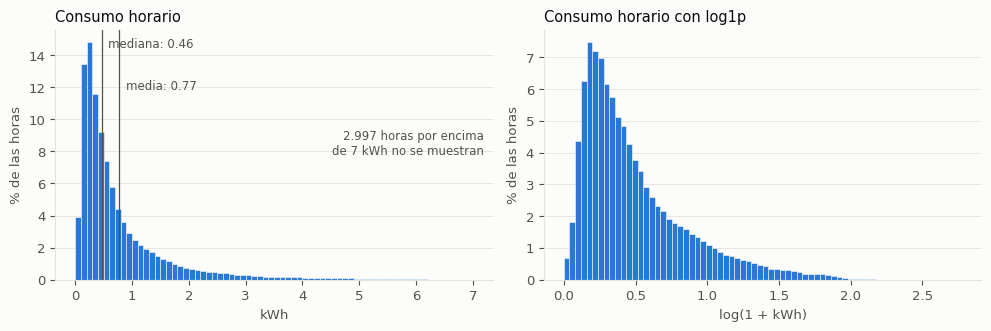

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
weights = np.full(len(demand), 100 / len(demand))

ax = axes[0]
ax.hist(demand, bins=70, range=(0, 7), weights=weights, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
top = ax.get_ylim()[1]
for value, label, height in [(demand.median(), "mediana", 0.97), (demand.mean(), "media", 0.80)]:
    ax.axvline(value, color=TEXT_SECONDARY, linewidth=0.9)
    ax.annotate(f"{label}: {value:.2f}", (value, top * height), xytext=(5, 0), textcoords="offset points",
                color=TEXT_SECONDARY, fontsize=8.5, va="top")
hidden_hours = f"{int(demand.gt(7).sum()):,}".replace(",", ".")
ax.text(0.98, 0.5, f"{hidden_hours} horas por encima\nde 7 kWh no se muestran",
        transform=ax.transAxes, ha="right", color=TEXT_SECONDARY, fontsize=8.5)
ax.set_title("Consumo horario", loc="left")
ax.set_xlabel("kWh")
ax.set_ylabel("% de las horas")

ax = axes[1]
ax.hist(np.log1p(demand), bins=70, range=(0, np.log1p(15)), weights=weights, color=BLUE,
        edgecolor=SURFACE, linewidth=0.4)
ax.set_title("Consumo horario con log1p", loc="left")
ax.set_xlabel("log(1 + kWh)")
ax.set_ylabel("% de las horas")

fig.tight_layout()
plt.show()

**Resultado.** La mayor parte de las horas está entre 0,1 y 1 kWh, con una cola que pasa de los 6 kWh. La media queda a la derecha de la mediana, arrastrada por esa cola. Con `log1p` la cola se acorta, pero la forma sigue inclinada a la derecha.

### 1.4 Los picos

Se mide qué parte de la energía reúnen las horas de mayor consumo, a qué hora se producen y si tienen que ver con la carga controlada (`CL`).

,umbral (kWh),% de la energía total
horas de mayor consumo,,
0.1%,6.461,1.0
1.0%,4.551,7.0
5.0%,2.561,24.1
10.0%,1.773,37.8


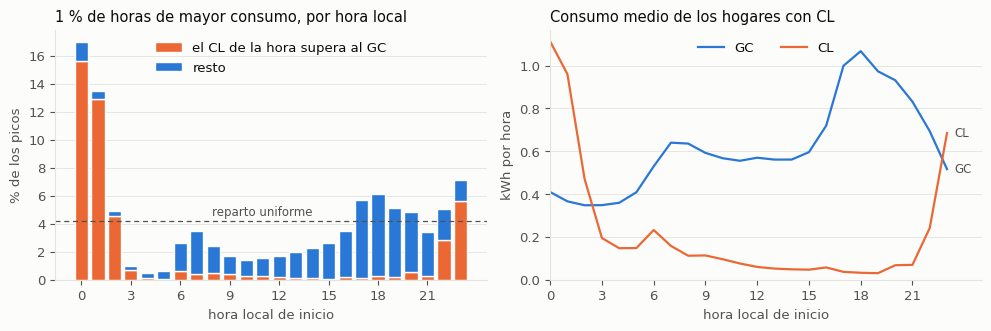

Filas de hogares con CL: 45.3 % del total, 62.8 % de los picos
Picos en los que el CL de la hora supera al GC: 46.8 %
Picos entre las 23:00 y las 03:00: 42.6 %; en ellos el CL supera al GC en el 90.9 %
Picos entre las 17:00 y las 22:00: 25.1 %; en ellos el CL supera al GC en el 5.5 %
Hogares con CL, de 00:00 a 01:00: CL medio 1.11 kWh, GC medio 0.41 kWh


In [8]:
ordered = np.sort(demand.to_numpy())[::-1]
total_energy = ordered.sum()
tail = []
for share in [0.001, 0.01, 0.05, 0.10]:
    n = int(len(ordered) * share)
    tail.append({
        "horas de mayor consumo": f"{share:.1%}",
        "umbral (kWh)": round(float(ordered[n - 1]), 3),
        "% de la energía total": round(100 * ordered[:n].sum() / total_energy, 1),
    })
display(pd.DataFrame(tail).set_index("horas de mayor consumo"))

peaks = train.loc[demand.gt(demand.quantile(0.99))]
cl_dominated = peaks["cl_kwh"].gt(peaks["gc_kwh"])
peak_share = (pd.crosstab(peaks["hora_local"], cl_dominated, normalize="all")
              .reindex(index=range(24), columns=[True, False], fill_value=0).mul(100))
cl_by_hour = train.loc[train["has_cl"]].groupby("hora_local")[["gc_kwh", "cl_kwh"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
hours = peak_share.index
ax.bar(hours, peak_share[True], width=0.8, color=ORANGE, edgecolor=SURFACE, linewidth=1,
       label="el CL de la hora supera al GC")
ax.bar(hours, peak_share[False], bottom=peak_share[True], width=0.8, color=BLUE, edgecolor=SURFACE,
       linewidth=1, label="resto")
ax.axhline(100 / 24, color=TEXT_SECONDARY, linewidth=0.9, linestyle=(0, (4, 3)))
ax.annotate("reparto uniforme", (11, 100 / 24), xytext=(0, 4), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=8.5, ha="center")
ax.set_title("1 % de horas de mayor consumo, por hora local", loc="left")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("% de los picos")
ax.legend(loc="upper center")

ax = axes[1]
for column, label, color in [("gc_kwh", "GC", BLUE), ("cl_kwh", "CL", ORANGE)]:
    ax.plot(cl_by_hour.index, cl_by_hour[column], color=color, label=label)
    ax.annotate(label, (23, cl_by_hour[column].iloc[-1]), xytext=(5, 0), textcoords="offset points",
                color=TEXT_SECONDARY, fontsize=8.5, va="center")
ax.set_title("Consumo medio de los hogares con CL", loc="left")
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 25)
ax.set_ylim(bottom=0)
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("kWh por hora")
ax.legend(loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

print(f"Filas de hogares con CL: {100 * train['has_cl'].mean():.1f} % del total, "
      f"{100 * peaks['has_cl'].mean():.1f} % de los picos")
print(f"Picos en los que el CL de la hora supera al GC: {100 * cl_dominated.mean():.1f} %")
for label, window in [("23:00 y las 03:00", peaks["hora_local"].isin([23, 0, 1, 2])),
                      ("17:00 y las 22:00", peaks["hora_local"].between(17, 21))]:
    print(f"Picos entre las {label}: {100 * window.mean():.1f} %; "
          f"en ellos el CL supera al GC en el {100 * cl_dominated[window].mean():.1f} %")
print(f"Hogares con CL, de 00:00 a 01:00: CL medio {cl_by_hour.loc[0, 'cl_kwh']:.2f} kWh, "
      f"GC medio {cl_by_hour.loc[0, 'gc_kwh']:.2f} kWh")

**Resultado.** El 1 % de las horas con más consumo (por encima de 4,55 kWh) reúne el 7 % de la energía, y el 10 % (por encima de 1,77 kWh) el 38 %. Los picos más altos no se producen en el pico de la tarde, sino alrededor de la medianoche: el 43 % del 1 % superior cae entre las 23:00 y las 03:00. Detrás está la carga controlada. Los hogares con `CL` son el 45 % de las filas, pero el 63 % de los picos, y en el 47 % de los picos el `CL` de esa hora supera al `GC`. En esos hogares el `CL` medio es de 1,1 kWh entre las 00:00 y la 01:00, frente a 0,4 kWh de `GC`: es la carga separada que funciona en horario valle, normalmente el calentador de agua. El gráfico separa dos tipos de pico: entre las 23:00 y las 03:00 el `CL` supera al `GC` en el 91 % de los picos, mientras que entre las 17:00 y las 22:00, donde cae otro 25 %, solo lo hace en el 5,5 %. Los picos de la tarde son de la actividad del hogar; los de medianoche, del calentador.

### 1.5 Media frente a mediana

Con una cola larga, la media y la mediana se separan. Importa porque, según la función de pérdida, un modelo aprende a predecir una o la otra. Se comparan primero por hora local y tipo de día con todos los hogares juntos, y después dentro de cada combinación de hogar, estación, tipo de día y hora, que es lo más parecido a lo que ve un modelo que conoce el hogar y el calendario.

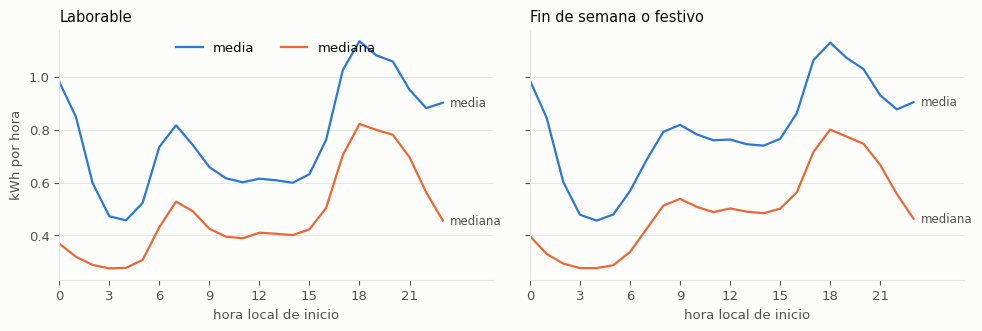

Media / mediana por hora local, todos los hogares juntos:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tipo_dia,,,,,,,,,,,,,,,,,,,,,,,,
laborable,2.66,2.66,2.08,1.72,1.65,1.71,1.71,1.55,1.51,1.55,1.56,1.55,1.50,1.50,1.49,1.49,1.51,1.46,1.38,1.35,1.36,1.37,1.57,1.98
fin de semana o festivo,2.49,2.56,2.05,1.73,1.65,1.67,1.69,1.61,1.54,1.52,1.54,1.56,1.52,1.52,1.53,1.53,1.53,1.49,1.41,1.38,1.38,1.40,1.58,1.95


Combinaciones hogar × estación × tipo de día × hora: 57,600 (con mediana 0: 0)


,count,mean,std,min,10%,25%,50%,75%,90%,max
media / mediana,57600.0,1.38,0.626,0.52,1.009,1.083,1.224,1.476,1.863,30.286


Si en cada combinación se tomara la mediana en lugar de la media, la energía total sería un 17.7 % menor


In [9]:
by_hour = train.groupby(["tipo_dia", "hora_local"], observed=True)["demand_kwh"].agg(media="mean", mediana="median")
by_hour["media / mediana"] = by_hour["media"] / by_hour["mediana"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, day_type in zip(axes, ["laborable", "fin de semana o festivo"]):
    part = by_hour.loc[day_type]
    for column, color in [("media", BLUE), ("mediana", ORANGE)]:
        ax.plot(part.index, part[column], color=color, label=column)
        ax.annotate(column, (23, part[column].iloc[-1]), xytext=(5, 0), textcoords="offset points",
                    color=TEXT_SECONDARY, fontsize=8.5, va="center")
    ax.set_title(day_type.capitalize(), loc="left")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 26)
    ax.set_xlabel("hora local de inicio")
axes[0].set_ylabel("kWh por hora")
axes[0].legend(loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

print("Media / mediana por hora local, todos los hogares juntos:")
display(by_hour["media / mediana"].unstack("hora_local").round(2))

cells = train.groupby(["customer", "estacion", "tipo_dia", "hora_local"], observed=True)["demand_kwh"].agg(
    media="mean", mediana="median", horas="size")
ratio = cells["media"] / cells["mediana"]
print(f"Combinaciones hogar × estación × tipo de día × hora: {len(cells):,} "
      f"(con mediana 0: {int(cells['mediana'].eq(0).sum())})")
display(ratio.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3).to_frame("media / mediana").T)

energy_gap = 1 - cells["mediana"].mul(cells["horas"]).sum() / cells["media"].mul(cells["horas"]).sum()
print(f"Si en cada combinación se tomara la mediana en lugar de la media, "
      f"la energía total sería un {100 * energy_gap:.1f} % menor")

**Resultado.** Con todos los hogares juntos, la media supera a la mediana entre un 35 % y un 55 % durante el día, y es hasta 2,7 veces mayor a la medianoche, porque a esa hora se mezclan hogares con y sin carga controlada. Dentro de cada hogar, estación, tipo de día y hora la diferencia es menor, pero no desaparece: la media es, en la mediana de las combinaciones, un 22 % mayor que la mediana, y en una de cada cuatro lo es en más de un 47 %. Por tanto, aunque el modelo conozca el hogar y el calendario, predecir la media o la mediana da valores claramente distintos. La diferencia, además, se acumula al sumar horas: si en cada combinación se tomara la mediana en lugar de la media, la energía total sería un 17,7 % menor que la real.

## 2. Diferencias entre hogares

### 2.1 Nivel de consumo

Consumo medio diario de cada hogar en los dos años.

,count,mean,std,min,5%,25%,50%,75%,95%,max
kWh/día,300.0,18.56,7.39,6.59,9.08,12.74,16.85,23.6,32.83,38.72


Menor consumo: {146: 6.6, 50: 7.8, 117: 8.0}
Mayor consumo: {134: 38.7, 55: 36.1, 61: 35.7}


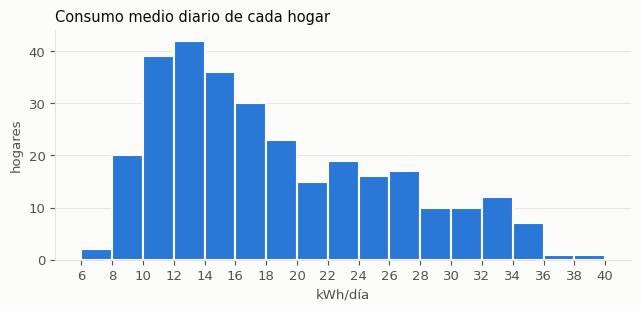

In [10]:
daily = train.groupby(["customer", "fecha_local"])["demand_kwh"].sum()
customers = pd.DataFrame({
    "kwh_dia": daily.groupby("customer").mean(),
    "capacidad_kwp": train.groupby("customer")["generator_capacity_kwp"].first(),
    "has_cl": train.groupby("customer")["has_cl"].any(),
})
display(customers["kwh_dia"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_frame("kWh/día").T)
print("Menor consumo:", customers["kwh_dia"].nsmallest(3).round(1).to_dict())
print("Mayor consumo:", customers["kwh_dia"].nlargest(3).round(1).to_dict())

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bins = np.arange(6, 42, 2)
ax.hist(customers["kwh_dia"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.set_xticks(bins)  # una marca en cada borde, para que ningún número quede en el centro de una barra
ax.set_title("Consumo medio diario de cada hogar", loc="left")
ax.set_xlabel("kWh/día")
ax.set_ylabel("hogares")
fig.tight_layout()
plt.show()

**Resultado.** El consumo medio va de 6,6 kWh/día (hogar 146) a 38,7 (hogar 134), casi 6 veces más. La mediana es 16,8 kWh/día, y el 90 % central de los hogares está entre 9,1 y 32,8. Un mismo error, por ejemplo 0,2 kWh por hora, no pesa lo mismo en un hogar que en otro.

### 2.2 Relación con lo que se sabe de cada hogar

De cada hogar solo se conoce si tiene carga controlada, la potencia fotovoltaica instalada y el código postal. El código postal no se analiza: hay 100 códigos para 300 hogares, unos tres por código, demasiado pocos para comparar zonas, y el clima es el mismo para todos (G12 en `docs/data/gaps.md`). Se comprueba si las otras dos explican el nivel de consumo.

In [11]:
has_cl_changes = train.groupby("customer")["has_cl"].nunique().gt(1).sum()
print("Hogares cuyo has_cl cambia entre los dos años:", int(has_cl_changes))
display(customers.groupby("has_cl")["kwh_dia"].describe().round(2))
rho = customers["kwh_dia"].corr(customers["capacidad_kwp"], method="spearman")
print(f"Correlación de Spearman entre consumo diario y potencia FV: {rho:.2f}")

Hogares cuyo has_cl cambia entre los dos años: 0


,count,mean,std,min,25%,50%,75%,max
has_cl,,,,,,,,
False,164.0,17.34,6.97,7.84,12.09,14.99,21.36,38.72
True,136.0,20.02,7.63,6.59,14.15,19.17,25.50,35.67


Correlación de Spearman entre consumo diario y potencia FV: 0.17


**Resultado.** 136 hogares tienen carga controlada y ninguno cambia entre los dos años. Consumen algo más (mediana de 19,2 kWh/día frente a 15,0), pero los dos grupos se solapan mucho. La potencia FV apenas tiene relación con el consumo (correlación de Spearman 0,17). Ninguna de las dos explica el nivel de un hogar; ese nivel solo se conoce por su propio histórico.

### 2.3 Variabilidad

Se calcula el coeficiente de variación (desviación / media) del consumo horario y del diario de cada hogar.

In [12]:
customers["cv_horario"] = train.groupby("customer")["demand_kwh"].agg(lambda s: s.std() / s.mean())
customers["cv_diario"] = daily.groupby("customer").agg(lambda s: s.std() / s.mean())
display(customers[["cv_horario", "cv_diario"]].describe(percentiles=[0.05, 0.5, 0.95]).round(2).T)
rho = customers["kwh_dia"].corr(customers["cv_horario"], method="spearman")
print(f"Correlación de Spearman entre consumo diario y variabilidad horaria: {rho:.2f}")

,count,mean,std,min,5%,50%,95%,max
cv_horario,300.0,1.05,0.28,0.37,0.65,1.02,1.57,2.10
cv_diario,300.0,0.41,0.16,0.17,0.21,0.40,0.69,1.08


Correlación de Spearman entre consumo diario y variabilidad horaria: -0.37


**Resultado.** Hora a hora, la desviación de un hogar típico es igual a su media (coeficiente de variación mediano de 1,02), con hogares entre 0,37 y 2,10. Al sumar el día la variabilidad baja a 0,40, porque las horas altas y bajas se compensan. Los hogares que más consumen son algo más regulares (Spearman de −0,37 entre nivel y variabilidad horaria).

### 2.4 Forma del perfil diario

Para comparar la forma sin que influya el nivel, el perfil medio de cada hogar por hora local se divide por su media. En el gráfico cada fila es un hogar, ordenados por la hora de su pico.

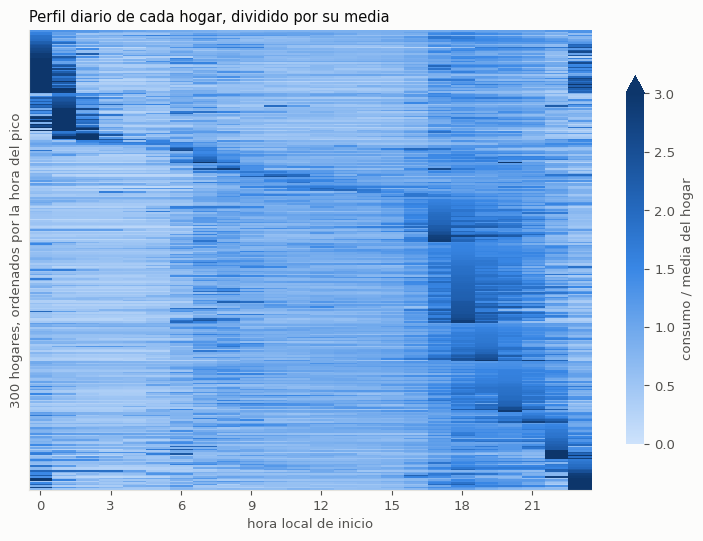

Hora del pico según si el hogar tiene CL:


tiene CL,False,True,total
hora del pico,,,
00:00-06:00,6,69,75
06:00-12:00,18,7,25
12:00-17:00,6,3,9
17:00-22:00,124,23,147
22:00-24:00,10,34,44
total,164,136,300


Hogares con CL y pico de madrugada: 69. Hora del pico si se mira solo el GC:


,00:00-06:00,06:00-12:00,12:00-17:00,17:00-22:00,22:00-24:00
hogares,4,3,3,54,5


Correlación de cada perfil con el perfil medio:


,count,mean,std,min,10%,25%,50%,75%,max
correlación,300.0,0.55,0.27,-0.41,0.17,0.39,0.62,0.75,0.92


In [13]:
profiles = train.groupby(["customer", "hora_local"])["demand_kwh"].mean().unstack()
profiles_norm = profiles.div(profiles.mean(axis=1), axis=0)
peak_hour = profiles_norm.idxmax(axis=1)

order = profiles_norm.assign(pico=peak_hour, altura=profiles_norm.max(axis=1)).sort_values(["pico", "altura"]).index
fig, ax = plt.subplots(figsize=(7.5, 5.5))
image = ax.imshow(profiles_norm.loc[order].to_numpy(), aspect="auto", cmap=BLUE_RAMP, vmin=0, vmax=3,
                  interpolation="nearest")
ax.grid(False)
ax.set_xticks(range(0, 24, 3))
ax.set_yticks([])
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("300 hogares, ordenados por la hora del pico")
ax.set_title("Perfil diario de cada hogar, dividido por su media", loc="left")
colorbar = fig.colorbar(image, ax=ax, shrink=0.8, extend="max")
colorbar.set_label("consumo / media del hogar")
colorbar.outline.set_visible(False)
fig.tight_layout()
plt.show()

PEAK_BINS = [-1, 5, 11, 16, 21, 23]
PEAK_LABELS = ["00:00-06:00", "06:00-12:00", "12:00-17:00", "17:00-22:00", "22:00-24:00"]
peak_group = pd.cut(peak_hour, PEAK_BINS, labels=PEAK_LABELS).rename("hora del pico")
print("Hora del pico según si el hogar tiene CL:")
display(pd.crosstab(peak_group, customers["has_cl"].rename("tiene CL"), margins=True, margins_name="total"))

gc_peak = train.groupby(["customer", "hora_local"])["gc_kwh"].mean().unstack().idxmax(axis=1)
night_cl = customers["has_cl"] & peak_group.eq("00:00-06:00")
print(f"Hogares con CL y pico de madrugada: {int(night_cl.sum())}. Hora del pico si se mira solo el GC:")
display(pd.cut(gc_peak[night_cl], PEAK_BINS, labels=PEAK_LABELS).value_counts(sort=False).to_frame("hogares").T)

mean_profile = profiles_norm.mean()
similarity = profiles_norm.apply(lambda row: np.corrcoef(row, mean_profile)[0, 1], axis=1)
print("Correlación de cada perfil con el perfil medio:")
similarity.describe(percentiles=[0.1, 0.25, 0.5, 0.75]).round(2).to_frame("correlación").T

**Resultado.** Hay dos formas dominantes:

- **Pico de tarde.** 147 hogares tienen el pico entre las 17:00 y las 22:00, y casi todos (124) no tienen carga controlada.
- **Pico de madrugada.** 75 hogares tienen el pico entre las 00:00 y las 06:00, y 69 de ellos tienen carga controlada. Si en esos 69 se mira solo el `GC`, la mayoría (54) tiene el pico por la tarde: el pico de madrugada es el calentador de agua, no la actividad del hogar.

El resto tiene el pico entre las 22:00 y las 24:00 (44 hogares, también con mayoría de carga controlada), por la mañana (25) o a mediodía (9). La correlación de cada perfil con el perfil medio tiene una mediana de 0,62, pero en un 10 % de los hogares es inferior a 0,17: su forma diaria no se parece a la media.

### 2.5 Periodos de casa vacía

Se buscan periodos en que el hogar está vacío, por vacaciones o mudanza. El primer criterio es el más directo: días en que el hogar consume menos del 20 % de su mediana diaria, y rachas de al menos 3 días seguidos así.

Días por debajo del umbral: 1420 | hogares: 56
Rachas de 3 días o más: 76 | hogares: 37 | días: 1287
Mes de inicio de las rachas: {1: 4, 2: 6, 3: 1, 4: 3, 5: 5, 6: 7, 7: 13, 8: 4, 9: 4, 10: 7, 11: 8, 12: 14}
Rachas que empiezan en diciembre, por año: {2010: 9, 2011: 5}
Rachas que empiezan en julio:


,inicio,fin,dias
customer,,,
6,2010-07-01,2010-07-14,14
81,2010-07-01,2010-10-21,113
191,2010-07-01,2010-10-22,114
233,2010-07-01,2010-07-20,20
32,2010-07-04,2010-07-10,7
174,2010-07-06,2010-07-15,10
226,2010-07-06,2010-07-11,6
134,2010-07-07,2010-07-17,11
232,2010-07-10,2010-07-14,5


Rachas más largas:


,inicio,fin,dias
customer,,,
191,2010-07-01,2010-10-22,114
81,2010-07-01,2010-10-21,113
99,2011-05-30,2011-08-29,92
229,2010-12-28,2011-02-24,59
151,2011-11-13,2012-01-02,51
146,2011-12-10,2012-01-25,47
229,2010-09-24,2010-11-09,47
229,2012-02-21,2012-03-30,39
146,2012-03-13,2012-04-17,36


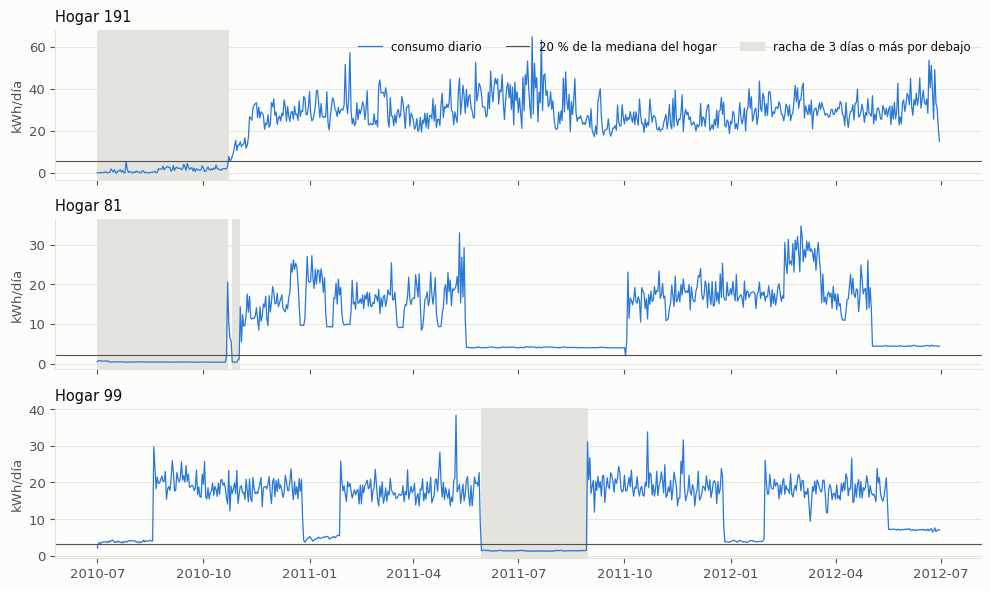

In [14]:
daily_df = daily.rename("kwh").reset_index().sort_values(["customer", "fecha_local"], ignore_index=True)
daily_df = daily_df.join(
    train.groupby(["customer", "fecha_local"])["gc_kwh"].median().rename("gc_hora_tipica"),
    on=["customer", "fecha_local"],
)


def find_runs(flags, min_days=3):
    """Rachas de días seguidos marcados en flags (alineado con daily_df) de al menos min_days días."""
    marked = pd.Series(flags.to_numpy(), index=daily_df.index)
    segment = marked.ne(marked.groupby(daily_df["customer"]).shift()).cumsum()
    runs = (
        daily_df.loc[marked]
        .assign(tramo=segment[marked])
        .groupby(["customer", "tramo"])
        .agg(inicio=("fecha_local", "min"), fin=("fecha_local", "max"), dias=("fecha_local", "size"))
        .reset_index()
        .drop(columns="tramo")
    )
    return runs.loc[runs["dias"].ge(min_days)].reset_index(drop=True)


low_total = daily_df["kwh"] < 0.2 * daily_df.groupby("customer")["kwh"].transform("median")
long_runs = find_runs(low_total)

print("Días por debajo del umbral:", int(low_total.sum()),
      "| hogares:", daily_df.loc[low_total, "customer"].nunique())
print("Rachas de 3 días o más:", len(long_runs), "| hogares:", long_runs["customer"].nunique(),
      "| días:", int(long_runs["dias"].sum()))
print("Mes de inicio de las rachas:", long_runs["inicio"].dt.month.value_counts().sort_index().to_dict())
print("Rachas que empiezan en diciembre, por año:",
      long_runs.loc[long_runs["inicio"].dt.month.eq(12), "inicio"].dt.year.value_counts().sort_index().to_dict())
print("Rachas que empiezan en julio:")
display(long_runs.loc[long_runs["inicio"].dt.month.eq(7)].sort_values("inicio").set_index("customer"))
print("Rachas más largas:")
display(long_runs.sort_values("dias", ascending=False).head(10).set_index("customer"))

examples = long_runs.sort_values("dias", ascending=False).drop_duplicates("customer")["customer"].head(3)
fig, axes = plt.subplots(len(examples), 1, figsize=(10, 6), sharex=True)
for ax, customer in zip(axes, examples):
    series = daily.loc[customer]
    for run in long_runs.loc[long_runs["customer"].eq(customer)].itertuples():
        ax.axvspan(run.inicio, run.fin + pd.Timedelta(days=1), color=GRID, linewidth=0)
    ax.plot(series.index, series.to_numpy(), color=BLUE, linewidth=0.9)
    ax.axhline(0.2 * series.median(), color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_title(f"Hogar {customer}", loc="left")
    ax.set_ylabel("kWh/día")
axes[0].legend(
    handles=[Line2D([], [], color=BLUE, linewidth=0.9, label="consumo diario"),
             Line2D([], [], color=TEXT_SECONDARY, linewidth=0.8, label="20 % de la mediana del hogar"),
             Patch(color=GRID, label="racha de 3 días o más por debajo")],
    loc="upper right", ncols=3, fontsize=8.5,
)
fig.tight_layout()
plt.show()

**Resultado.** 56 hogares tienen algún día por debajo del umbral, 1.420 días en total, y la mayoría forman rachas: hay 76 rachas de 3 días o más en 37 hogares, con 1.287 días. Las más largas duran más de tres meses: los hogares 191 y 81 apenas consumen desde el inicio de los datos hasta finales de octubre de 2010, y el 99 desde finales de mayo hasta finales de agosto de 2011. No son errores de medición, pero no representan el comportamiento habitual del hogar.

Las rachas empiezan sobre todo en diciembre (14 de 76) y en julio (13). Diciembre se repite los dos años (9 rachas en 2010 y 5 en 2011) y coincide con las vacaciones de verano. Julio, no. De las 13 rachas de julio, 4 empiezan el 1 de julio de 2010, el primer día de datos: esos hogares ya estaban casi sin consumo al empezar el conjunto, y no se sabe cuándo empezó la racha. Otras 7 son de julio de 2010, duran de 4 a 11 días y empiezan entre el 4 y el 18 de julio, lo que sí encaja con una salida en vacaciones de invierno. En julio de 2011 solo hay 2, y las dos son del hogar 240. Con dos años no se puede decir si julio es un mes de casas vacías.

El gráfico muestra además algo que este criterio no capta. El hogar 81 desde junio hasta octubre de 2011 y desde mayo de 2012, y el 99 en varios periodos, tienen un consumo diario plano, de unos 4 o 7 kWh, que apenas cambia de un día a otro. Es demasiado alto para quedar por debajo del umbral. Se miran sus valores horarios.

In [15]:
for customer, day in [(81, "2011-07-01"), (99, "2012-05-20")]:
    hours = train.loc[train["customer"].eq(customer) & train["fecha_local"].eq(pd.Timestamp(day))]
    print(f"Hogar {customer}, {day}, kWh por hora:")
    display(hours.set_index("hora_local")[["gc_kwh", "cl_kwh"]].T.round(3))

Hogar 81, 2011-07-01, kWh por hora:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
gc_kwh,0.023,0.028,0.024,0.023,0.023,0.023,0.023,0.029,0.023,0.024,0.023,0.314,0.024,0.024,0.023,0.024,0.029,0.023,0.023,0.023,0.023,0.022,1.124,2.038
cl_kwh,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Hogar 99, 2012-05-20, kWh por hora:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
gc_kwh,0.159,0.157,0.152,0.136,0.153,0.153,0.151,0.134,0.238,0.181,0.163,0.151,0.16,0.168,0.167,0.158,0.154,0.171,0.194,0.241,0.181,0.164,0.136,0.144
cl_kwh,0.000,0.000,0.000,0.000,1.032,0.000,0.000,0.000,0.000,0.000,0.000,0.991,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.209,0.000


**Resultado.** Los dos días son de casa vacía con aparatos que siguen funcionando. En el hogar 81 el `GC` se queda en unos 0,02 kWh casi todas las horas, que es el consumo de los aparatos en reposo, salvo tres horas: unos 0,3 kWh a las 11:00 y 1,1 y 2,0 kWh a las 22:00 y las 23:00. Son cargas con temporizador, y se repiten igual todos los días del periodo. En el hogar 99 el `GC` se queda en unos 0,15 kWh todo el día, y el `CL`, el calentador de agua, se sigue encendiendo unas pocas horas (a las 04:00, las 11:00 y las 22:00). El total del día no detecta estos casos.

Por eso se prueba un segundo criterio: la **hora típica** del día, es decir, la mediana de las 24 horas de `GC`. Cuando la casa está vacía, la hora típica es solo el consumo en reposo, aunque haya algunas horas con cargas programadas. Se marcan los días cuya hora típica es menor que una fracción de la habitual del hogar (la mediana de ese valor en todos sus días), y se comparan varios umbrales.

In [16]:
typical_ratio = daily_df["gc_hora_tipica"] / daily_df.groupby("customer")["gc_hora_tipica"].transform("median")
comparison = []
for threshold in [0.20, 0.25, 0.30, 0.35]:
    flagged = typical_ratio < threshold
    threshold_runs = find_runs(flagged)
    comparison.append({
        "umbral": f"{threshold:.0%}",
        "días marcados": int(flagged.sum()),
        "hogares": daily_df.loc[flagged, "customer"].nunique(),
        "rachas de 3 días o más": len(threshold_runs),
        "hogares con rachas": threshold_runs["customer"].nunique(),
        "días en rachas": int(threshold_runs["dias"].sum()),
        "también con total < 20 %": int((flagged & low_total).sum()),
    })
display(pd.DataFrame(comparison).set_index("umbral"))
print("Días marcados con el total < 20 %:", int(low_total.sum()))

typical_runs = find_runs(typical_ratio < 0.30)
print("\nEjemplo con el umbral del 30 %. Rachas más largas:")
display(typical_runs.sort_values("dias", ascending=False).head(8).set_index("customer"))
print("Rachas del hogar 81:")
typical_runs.loc[typical_runs["customer"].eq(81)].set_index("customer")

,días marcados,hogares,rachas de 3 días o más,hogares con rachas,días en rachas,también con total < 20 %
umbral,,,,,,
20%,1458,43,70,33,1324,1040
25%,2154,76,133,53,1920,1234
30%,3105,106,209,85,2680,1329
35%,4315,143,300,112,3482,1390


Días marcados con el total < 20 %: 1420

Ejemplo con el umbral del 30 %. Rachas más largas:


,inicio,fin,dias
customer,,,
229,2010-09-23,2011-02-24,155
146,2011-10-24,2012-02-25,125
191,2010-07-01,2010-10-26,118
81,2010-07-01,2010-10-20,112
99,2011-05-29,2011-08-29,93
81,2011-07-20,2011-10-02,75
146,2012-05-06,2012-06-30,56
151,2011-11-12,2012-01-02,52


Rachas del hogar 81:


,inicio,fin,dias
customer,,,
81,2010-07-01,2010-10-20,112
81,2010-10-25,2010-10-30,6
81,2011-05-17,2011-05-26,10
81,2011-05-28,2011-06-06,10
81,2011-06-08,2011-07-07,30
81,2011-07-09,2011-07-18,10
81,2011-07-20,2011-10-02,75
81,2012-05-03,2012-06-04,33
81,2012-06-09,2012-06-19,11


**Resultado.** Con un umbral del 20 %, la hora típica marca un número de días parecido al del total (1.458 frente a 1.420), aunque solo coinciden 1.040. Al subir el umbral el número crece deprisa: 3.105 días en 106 hogares con el 30 % y 4.315 en 143 con el 35 %. Con el 30 % se recogen casi todos los días del primer criterio (1.329 de 1.420) y además los periodos planos que faltaban. Por ejemplo, el hogar 81 pasa a tener una racha de 75 días entre julio y octubre de 2011 y otra de 33 en mayo de 2012, y el 229 una de 155 días entre septiembre de 2010 y febrero de 2011. A la vez, cuanto más alto es el umbral, más fácil es marcar días en que el hogar simplemente consume poco sin estar vacío. Ninguno de los dos criterios es definitivo, y elegir uno y su umbral queda entre las preguntas abiertas.

### 2.6 Cambios de nivel entre los dos años

Para cada hogar se divide la mediana de su consumo diario en 2011-2012 entre la de 2010-2011.

,count,mean,std,min,5%,25%,50%,75%,95%,max
cociente,300.0,0.963,0.158,0.247,0.717,0.886,0.964,1.041,1.184,1.774


Hogares que bajan a 2/3 o menos: 9 | que suben 1,5 veces o más: 4


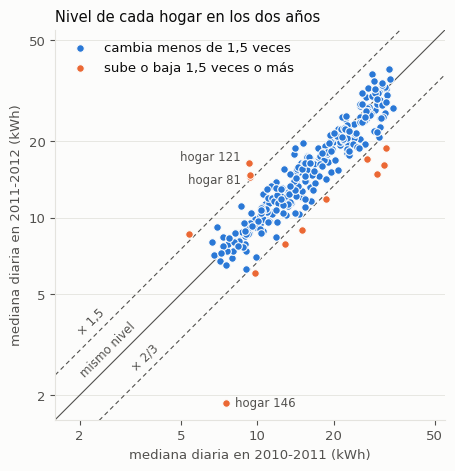

año,2010-2011,2011-2012,cociente
customer,,,
146,7.57,1.87,0.25
168,29.67,14.91,0.50
158,31.61,16.11,0.51
17,32.34,18.85,0.58
171,15.06,8.93,0.59
121,9.27,16.45,1.77
20,5.39,8.63,1.60
81,9.33,14.80,1.59
41,9.36,14.52,1.55


In [17]:
daily_df["año"] = np.where(daily_df["fecha_local"] < pd.Timestamp("2011-07-01"), "2010-2011", "2011-2012")
levels = daily_df.groupby(["customer", "año"])["kwh"].median().unstack()
levels["cociente"] = levels["2011-2012"] / levels["2010-2011"]

display(levels["cociente"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_frame("cociente").T)
print("Hogares que bajan a 2/3 o menos:", int(levels["cociente"].le(2 / 3).sum()),
      "| que suben 1,5 veces o más:", int(levels["cociente"].ge(1.5).sum()))

changed = levels["cociente"].le(2 / 3) | levels["cociente"].ge(1.5)
limits = np.array([1.6, 55])
fig, ax = plt.subplots(figsize=(5.2, 4.8))
for factor, style in [(1, "-"), (1.5, (0, (4, 3))), (2 / 3, (0, (4, 3)))]:
    ax.plot(limits, limits * factor, color=TEXT_SECONDARY, linewidth=0.8, linestyle=style, zorder=1)
for x, y, label in [(2.8, 2.8, "mismo nivel"), (2.4, 3.6, "× 1,5"), (3.9, 2.6, "× 2/3")]:
    ax.annotate(label, (x, y), xytext=(-3, 3), textcoords="offset points", rotation=45, rotation_mode="anchor",
                ha="center", va="bottom", color=TEXT_SECONDARY, fontsize=8.5)
for mask, color, label in [(~changed, BLUE, "cambia menos de 1,5 veces"),
                           (changed, ORANGE, "sube o baja 1,5 veces o más")]:
    ax.scatter(levels.loc[mask, "2010-2011"], levels.loc[mask, "2011-2012"], s=30, color=color,
               edgecolor=SURFACE, linewidth=0.8, zorder=2, label=label)
for customer, offset in [(146, (6, 0)), (121, (-6, 4)), (81, (-6, -4))]:
    ax.annotate(f"hogar {customer}", levels.loc[customer, ["2010-2011", "2011-2012"]].to_numpy(dtype=float),
                xytext=offset, textcoords="offset points", ha="left" if offset[0] > 0 else "right", va="center",
                color=TEXT_SECONDARY, fontsize=8.5)
ax.set_xscale("log")
ax.set_yscale("log")
ticks = [2, 5, 10, 20, 50]
ax.set_xticks(ticks, labels=ticks)
ax.set_yticks(ticks, labels=ticks)
ax.minorticks_off()
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal")
ax.set_title("Nivel de cada hogar en los dos años", loc="left")
ax.set_xlabel("mediana diaria en 2010-2011 (kWh)")
ax.set_ylabel("mediana diaria en 2011-2012 (kWh)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

pd.concat([levels.nsmallest(5, "cociente"), levels.nlargest(5, "cociente")]).round(2)

**Resultado.** La mayoría de los hogares mantiene su nivel: la mediana del cociente es 0,96 (un 4 % menos el segundo año), y la mitad central está entre 0,89 y 1,04. 13 hogares cambian por un factor de 1,5 o más: 9 bajan y 4 suben. En el gráfico, cada punto es un hogar y los que quedan fuera de las líneas discontinuas son esos 13. Las cuatro subidas son de hogares que consumían poco el primer año (entre 5,4 y 9,4 kWh/día); las bajadas aparecen en todos los niveles. El caso extremo es el 146, que el segundo año consume la cuarta parte que el primero. Es además el hogar que menos consume, tiene varias rachas de consumo casi nulo y es uno de los dos con la generación desplazada (`gg_unreliable`). En algunos hogares, como el 81, el cambio se debe a que un año tiene más días de casa vacía que el otro. En otros puede ser un cambio real en el hogar, como más o menos personas o aparatos nuevos, y con estos datos no siempre se puede distinguir.

## 3. Estacionalidades y calendario

Este bloque describe cómo cambia el consumo según el día de la semana, los festivos y la época del año, y comprueba que sigue la hora local. Como los niveles de los hogares son muy distintos (sección 2.1), el consumo de cada hogar se divide por su consumo horario medio de los dos años, igual que en la sección 2.4, y después se promedian los hogares. Así cada hogar pesa lo mismo, y un valor de 1 corresponde a una hora de consumo medio para ese hogar.

### 3.1 Día de la semana

Se compara el consumo medio de cada día de la semana y la forma de su perfil horario, sin contar los festivos. La diferencia de forma entre dos perfiles se mide así: cada perfil se divide por su media y se calcula la diferencia media absoluta, hora a hora. Un 5 % quiere decir que, de media, cada hora de un perfil se separa de la del otro un 5 % del consumo medio.

Consumo de cada día respecto a la media de lunes a viernes:


,lun,mar,mié,jue,vie,sáb,dom
cociente,0.997,1.0,1.0,1.002,1.001,1.042,1.061


Diferencia de forma entre los perfiles horarios de cada par de días (%):


,lun,mar,mié,jue,vie,sáb,dom
lun,0.0,1.0,1.5,2.1,3.2,9.6,9.9
mar,1.0,0.0,0.7,1.3,2.5,9.3,9.9
mié,1.5,0.7,0.0,1.1,2.4,9.2,10.0
jue,2.1,1.3,1.1,0.0,1.6,8.7,9.9
vie,3.2,2.5,2.4,1.6,0.0,7.7,9.0
sáb,9.6,9.3,9.2,8.7,7.7,0.0,3.4
dom,9.9,9.9,10.0,9.9,9.0,3.4,0.0


Consumo diario de fin de semana / consumo diario de laborable, en cada hogar:


,count,mean,std,min,5%,25%,50%,75%,95%,max
cociente,300.0,1.054,0.092,0.853,0.923,1.004,1.037,1.085,1.216,1.615


Hogares a menos de un 5 % de 1: 156 | por debajo de 1: 64 | por encima de 1,2: 21


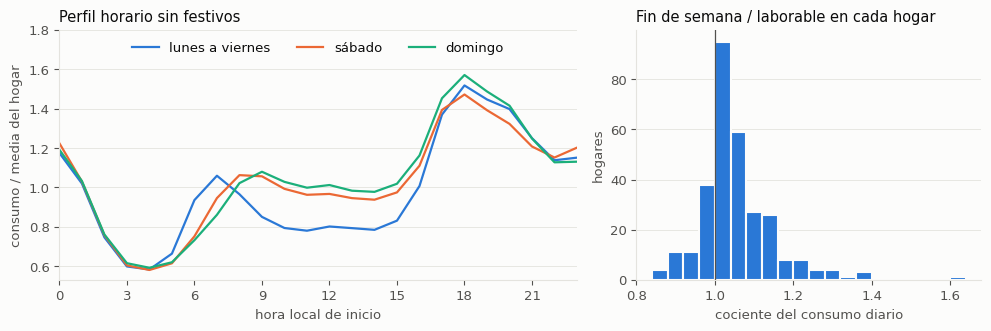

In [18]:
train["consumo_rel"] = train["demand_kwh"] / train.groupby("customer")["demand_kwh"].transform("mean")
days_rel = (
    train.groupby(["customer", "fecha_local"])
    .agg(consumo_rel=("consumo_rel", "mean"), dia_semana=("dia_semana", "first"), festivo=("festivo", "first"))
    .reset_index()
)
DAY_SHORT = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
MONTHS = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def shape_gap(a, b):
    """Diferencia media absoluta entre las formas de dos perfiles (cada uno dividido por su media), en %."""
    return 100 * float((a / a.mean() - b / b.mean()).abs().mean())


weekday_profiles = train.loc[~train["festivo"]].groupby(["dia_semana", "hora_local"])["consumo_rel"].mean().unstack()
weekday_profiles.index = DAY_SHORT
regular_days = days_rel.loc[~days_rel["festivo"]]
weekday_level = regular_days.groupby("dia_semana")["consumo_rel"].mean()
weekday_level.index = DAY_SHORT

print("Consumo de cada día respecto a la media de lunes a viernes:")
display((weekday_level / weekday_level.iloc[:5].mean()).round(3).to_frame("cociente").T)
print("Diferencia de forma entre los perfiles horarios de cada par de días (%):")
display(pd.DataFrame({b: {a: shape_gap(weekday_profiles.loc[a], weekday_profiles.loc[b]) for a in DAY_SHORT}
                      for b in DAY_SHORT}).round(1))

per_customer = (regular_days.assign(fin_de_semana=regular_days["dia_semana"].ge(5))
                .groupby(["customer", "fin_de_semana"])["consumo_rel"].mean().unstack())
weekend_ratio = per_customer[True] / per_customer[False]
print("Consumo diario de fin de semana / consumo diario de laborable, en cada hogar:")
display(weekend_ratio.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_frame("cociente").T)
print("Hogares a menos de un 5 % de 1:", int(weekend_ratio.sub(1).abs().lt(0.05).sum()),
      "| por debajo de 1:", int(weekend_ratio.lt(1).sum()), "| por encima de 1,2:", int(weekend_ratio.gt(1.2).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
lines = {"lunes a viernes": weekday_profiles.iloc[:5].mean(), "sábado": weekday_profiles.loc["sáb"],
         "domingo": weekday_profiles.loc["dom"]}
for (label, profile), color in zip(lines.items(), [BLUE, ORANGE, AQUA]):
    ax.plot(profile.index, profile.to_numpy(), color=color, label=label)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 23)
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("consumo / media del hogar")
ax.set_title("Perfil horario sin festivos", loc="left")
ax.set_ylim(top=1.8)
ax.legend(loc="upper center", ncols=3)

ax = axes[1]
ax.hist(weekend_ratio, bins=np.arange(0.84, 1.68, 0.04), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=TEXT_SECONDARY, linewidth=0.9)
ax.set_title("Fin de semana / laborable en cada hogar", loc="left")
ax.set_xlabel("cociente del consumo diario")
ax.set_ylabel("hogares")
fig.tight_layout()
plt.show()

**Resultado.** De lunes a viernes el consumo diario es prácticamente el mismo (todos a menos de un 0,3 % de su media) y la forma del perfil también: entre lunes y jueves las diferencias de forma van del 0,7 al 2,1 %. El viernes se separa algo más (del 1,6 al 3,2 %): consume un poco menos entre las 17:00 y las 21:00 y algo más a última hora. El sábado consume un 4 % más que un laborable y el domingo un 6 % más, y los dos tienen otra forma (entre un 7,7 y un 10 % de diferencia con los laborables): no tienen el pico de las 07:00, el consumo de la mañana llega más tarde, hacia las 08:00 o 09:00, y entre las 10:00 y las 15:00 es entre un 15 y un 30 % mayor que en un laborable. Entre sábado y domingo la diferencia es del 3,4 %, mucho menor que entre un laborable y el fin de semana. El domingo tiene un pico de tarde algo mayor, y el sábado consume más a última hora.

En cada hogar, el efecto en el nivel es pequeño y desigual. La mediana del cociente entre fin de semana y laborable es 1,04. En 156 hogares la diferencia es menor del 5 %, en 64 el fin de semana consume menos y en 21 consume más de un 20 % más. La diferencia entre laborables y fines de semana está sobre todo en la forma del día, no en el total.

### 3.2 Festivos, Navidad y vacaciones

En un festivo lo que cambia es sobre todo la rutina: no hay que madrugar ni salir de casa. Por eso aquí se compara la **forma** del perfil de cada día, no su nivel. Para cada día se calcula el perfil medio de los hogares, dividido por su media, y se compara con dos referencias tomadas de las cuatro semanas anteriores y las cuatro posteriores: la forma media de los laborables y la de los fines de semana. Con ellas se define un **índice de fin de semana**, que vale 0 si el día tiene la forma de un laborable de esas semanas y 1 si tiene la de un fin de semana. Es la proyección del perfil del día sobre la diferencia entre las dos referencias, así que puede salir algo por debajo de 0 o por encima de 1.

Las referencias son locales para que el índice no dependa de la época del año, porque la forma del perfil cambia con las estaciones (sección 3.3). En ellas no entran los festivos ni los días del 20 de diciembre al 10 de enero. Se omiten los 5 días que no tienen 24 horas (sección 0.2).

In [19]:
hours_in_day = train.groupby("fecha_local").size() / train["customer"].nunique()
full_days = hours_in_day.index[hours_in_day.eq(24)]
day_profiles = (train.loc[train["fecha_local"].isin(full_days)]
                .groupby(["fecha_local", "hora_local"])["consumo_rel"].mean().unstack())
shapes = day_profiles.div(day_profiles.mean(axis=1), axis=0).to_numpy()

calendar = days_rel.drop_duplicates("fecha_local").set_index("fecha_local").loc[full_days, ["dia_semana", "festivo"]]
month_day = calendar.index.month * 100 + calendar.index.day
christmas = (month_day >= 1220) | (month_day <= 110)
calendar["clase"] = np.select(
    [calendar["festivo"] & calendar["dia_semana"].lt(5), calendar["festivo"], calendar["dia_semana"].eq(5),
     calendar["dia_semana"].eq(6), christmas],
    ["festivo en laborable", "festivo en fin de semana", "sábado", "domingo", "laborable del 20-dic al 10-ene"],
    default="laborable",
)
is_weekday_ref = calendar["clase"].eq("laborable").to_numpy()
is_weekend_ref = (calendar["clase"].isin(["sábado", "domingo"]) & ~christmas).to_numpy()

dates = calendar.index.to_numpy()
offsets = np.abs(dates[:, None] - dates[None, :]) / np.timedelta64(1, "D")
weekend_index = []
for i in range(len(calendar)):
    near = offsets[i] <= 28
    near[i] = False
    weekday_ref = shapes[near & is_weekday_ref].mean(axis=0)
    weekend_ref = shapes[near & is_weekend_ref].mean(axis=0)
    direction = weekend_ref - weekday_ref
    weekend_index.append((shapes[i] - weekday_ref) @ direction / (direction @ direction))
calendar["indice"] = weekend_index

CLASS_ORDER = ["laborable", "sábado", "domingo", "festivo en laborable", "festivo en fin de semana",
               "laborable del 20-dic al 10-ene"]
print("Índice de fin de semana según el tipo de día:")
display(calendar.groupby("clase")["indice"].describe(percentiles=[0.05, 0.5, 0.95]).loc[CLASS_ORDER].round(2))

print("Festivos en día laborable:")
holiday_index = calendar.loc[calendar["clase"].eq("festivo en laborable"), ["indice"]].join(
    festivos.set_index("fecha")[["nombre", "día de la semana"]])
display(holiday_index[["nombre", "día de la semana", "indice"]].round(2))

christmas_days = calendar.loc[calendar["clase"].eq("laborable del 20-dic al 10-ene"), "indice"]
christmas_table = pd.DataFrame({
    "temporada": [f"{y}-{y + 1}" for y in christmas_days.index.year - (christmas_days.index.month == 1)],
    "día": christmas_days.index.strftime("%d-%m"),
    "orden": (christmas_days.index.month == 1) * 100 + christmas_days.index.day,
    "indice": christmas_days.to_numpy(),
})
day_order = christmas_table.drop_duplicates("día").sort_values("orden")["día"]
print("Índice de los laborables del 20 de diciembre al 10 de enero (los festivos y los fines de semana no aparecen):")
christmas_table.pivot(index="temporada", columns="día", values="indice")[day_order].round(2)

Índice de fin de semana según el tipo de día:


,count,mean,std,min,5%,50%,95%,max
clase,,,,,,,,
laborable,477.0,0.03,0.30,-0.74,-0.41,-0.00,0.57,1.23
sábado,101.0,0.93,0.32,0.00,0.51,0.89,1.47,2.04
domingo,95.0,1.02,0.39,0.04,0.56,0.95,1.90,2.49
festivo en laborable,18.0,1.14,0.43,0.07,0.66,1.10,1.72,2.08
festivo en fin de semana,9.0,1.22,0.33,0.89,0.91,1.14,1.77,1.98
laborable del 20-dic al 10-ene,26.0,0.61,0.49,-0.13,-0.05,0.57,1.30,1.86


Festivos en día laborable:


,nombre,día de la semana,indice
fecha_local,,,
2010-08-02,Bank Holiday,lunes,0.07
2010-10-04,Labour Day,lunes,1.42
2010-12-27,Boxing Day (observed),lunes,0.96
2010-12-28,Additional Day,martes,0.80
2011-01-03,New Year's Day (observed),lunes,1.34
2011-01-26,Australia Day,miércoles,1.66
2011-04-22,Good Friday,viernes,1.15
2011-04-25,ANZAC Day; Easter Monday,lunes,1.57
2011-06-13,Queen's Birthday,lunes,1.39


Índice de los laborables del 20 de diciembre al 10 de enero (los festivos y los fines de semana no aparecen):


día,20-12,21-12,22-12,23-12,24-12,28-12,29-12,30-12,31-12,03-01,04-01,05-01,06-01,07-01,09-01,10-01
temporada,,,,,,,,,,,,,,,,
2010-2011,0.05,-0.13,-0.08,0.35,1.19,NaN,0.66,0.85,1.32,NaN,0.83,1.00,1.22,1.2,NaN,0.36
2011-2012,0.07,0.09,0.52,0.61,NaN,0.52,0.63,0.44,NaN,0.76,1.86,0.51,0.72,NaN,0.26,0.05


**Resultado.** El índice separa bien los dos tipos de día: los laborables normales tienen una media de 0,03, y los sábados y domingos de 0,93 y 1,02. Pero un día suelto es ruidoso: la desviación típica está entre 0,3 y 0,4, y un 5 % de los laborables normales pasa de 0,57.

- **Festivos.** Se comportan como un domingo: los que caen en laborable tienen una mediana de 1,10. Todos están por encima de 0,75 salvo uno, el *Bank Holiday* del 2 de agosto de 2010, con 0,07: ese día se consume como en un laborable normal, lo esperable porque solo cierran los bancos. El 28 de diciembre de 2010, el festivo añadido a mano en la sección 0.3, tiene 0,80, como los otros festivos de Navidad.
- **Navidad.** Hasta el 21 de diciembre los laborables son normales (entre −0,13 y 0,09). Del 22 o el 23 de diciembre al 6 o el 7 de enero el índice está casi siempre entre 0,5 y 1,3, y el 9 y el 10 de enero baja a entre 0,05 y 0,36. Entre Navidad y Reyes los laborables se parecen más a un fin de semana que a un laborable, aunque no sean festivos.

El índice mide la forma del día, y la rutina no es lo único que la cambia: un día de mucho calor también la cambia, por el aire acondicionado de la tarde. Para separar los dos efectos se mira el índice de los laborables normales según la temperatura máxima del día (ERA5) y, después, la media semanal del índice de los laborables a lo largo de los dos años. En ella deberían aparecer las semanas en que muchos hogares no siguen la rutina de un laborable, como las vacaciones escolares.

Índice de los laborables normales según la temperatura máxima del día:


temp_max,hasta 25 °C,25-30 °C,30-35 °C,más de 35 °C
días,369.00,87.00,17.00,4.00
media,-0.01,0.07,0.43,0.78


Semanas con al menos 3 laborables: 104. Desviación típica de la media semanal: 0.28
Semanas en que el índice medio de los laborables es de 0,3 o más (fecha del lunes):


fecha_local,2010-07-05,2010-09-27,2010-10-04,2010-12-27,2011-01-03,2011-01-10,2011-01-17,2011-01-31,2011-04-18,2011-04-25,2011-07-11,2011-07-18,2011-11-07,2011-12-26,2012-01-02,2012-04-16
laborables,5.0,5.00,4.00,3.00,4.00,5.00,5.00,5.00,4.00,4.00,5.00,5.0,5.00,3.00,4.00,5.00
indice,0.5,0.31,0.55,0.95,1.06,0.31,0.35,0.85,0.32,0.48,0.41,0.3,0.33,0.53,0.96,0.52
temp_max,15.9,26.90,22.90,30.80,25.30,29.00,30.60,40.40,25.30,20.20,18.50,18.0,33.70,23.20,34.00,25.40


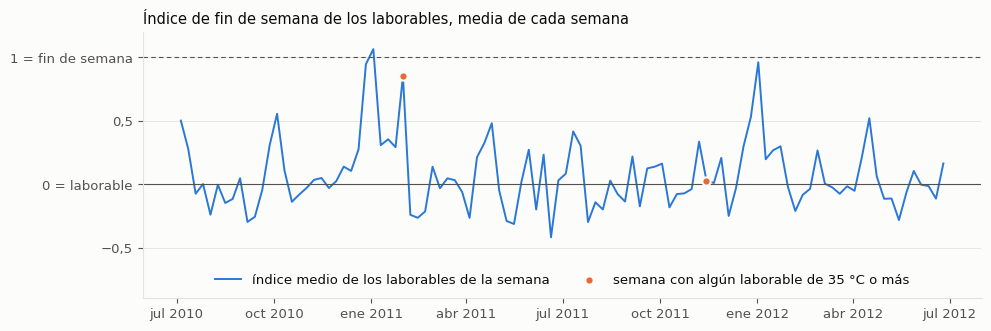

In [20]:
weather = pd.read_parquet(data_path, columns=["timestamp_utc", "temperature_2m"], filters=[("customer", "==", 1)])
weather_day = (weather["timestamp_utc"] - pd.Timedelta(hours=1)).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None).dt.normalize()
calendar["temp_max"] = weather.groupby(weather_day)["temperature_2m"].max()

regular_weekdays = calendar.loc[calendar["clase"].eq("laborable")]
heat_bins = pd.cut(regular_weekdays["temp_max"], [0, 25, 30, 35, 45],
                   labels=["hasta 25 °C", "25-30 °C", "30-35 °C", "más de 35 °C"])
print("Índice de los laborables normales según la temperatura máxima del día:")
display(regular_weekdays.groupby(heat_bins, observed=True)["indice"].agg(días="size", media="mean").round(2).T)

weekdays_only = calendar.loc[calendar["clase"].isin(["laborable", "laborable del 20-dic al 10-ene"])]
week_start = weekdays_only.index - pd.to_timedelta(weekdays_only.index.dayofweek, unit="D")
weekly = weekdays_only.groupby(week_start).agg(
    laborables=("indice", "size"), indice=("indice", "mean"), temp_max=("temp_max", "max"))
weekly = weekly.loc[weekly["laborables"].ge(3)]
high_weeks = weekly.loc[weekly["indice"].ge(0.3)]
print(f"Semanas con al menos 3 laborables: {len(weekly)}. "
      f"Desviación típica de la media semanal: {weekly['indice'].std():.2f}")
print("Semanas en que el índice medio de los laborables es de 0,3 o más (fecha del lunes):")
display(high_weeks.set_axis(high_weeks.index.strftime("%Y-%m-%d")).round(2).T)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(weekly.index, weekly["indice"].to_numpy(), color=BLUE, linewidth=1.4,
        label="índice medio de los laborables de la semana")
hot = weekly.loc[weekly["temp_max"].ge(35)]
ax.scatter(hot.index, hot["indice"], s=36, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=3,
           label="semana con algún laborable de 35 °C o más")
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.axhline(1, color=TEXT_SECONDARY, linewidth=0.8, linestyle=(0, (4, 3)))
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_yticklabels(["−0,5", "0 = laborable", "0,5", "1 = fin de semana"])
ticks = pd.date_range("2010-07-01", "2012-07-01", freq="3MS")
ax.set_xticks(ticks)
ax.set_xticklabels([f"{MONTHS[t.month - 1]} {t.year}" for t in ticks])
ax.set_title("Índice de fin de semana de los laborables, media de cada semana", loc="left")
ax.set_ylim(-0.9, 1.2)
ax.legend(loc="lower center", ncols=2)
fig.tight_layout()
plt.show()

**Resultado.** El calor también sube el índice. Los laborables normales de hasta 30 °C están en torno a 0 (−0,01 y 0,07), pero los de 30 a 35 °C tienen una media de 0,43 y los de más de 35 °C, de 0,78. Son pocos días (17 y 4), pero en ellos el consumo de la tarde, seguramente el aire acondicionado, da al perfil una forma parecida a la de un fin de semana. Por eso el índice solo indica un cambio de rutina en los días que no son muy calurosos.

En la serie semanal hay 16 semanas con un índice medio de 0,3 o más:

- **Navidad y Año Nuevo**: 4 semanas, de 0,53 a 1,06.
- **Calor**: la ola de calor de principios de febrero de 2011 (0,85, con 40 °C) y la semana del 7 de noviembre de 2011 (0,33, con 33,7 °C).
- **Las otras 10**, con valores de 0,30 a 0,55, caen en cuatro épocas: julio (2010 y 2011), la segunda quincena de abril (2011 y 2012), finales de septiembre y principios de octubre (2010) y mediados de enero (2011).

Esas cuatro épocas son las de las vacaciones escolares en Nueva Gales del Sur, que tienen dos semanas en abril, julio y septiembre-octubre, y las de verano, hasta finales de enero. Las fechas exactas de 2010 a 2012 no se han podido comprobar, porque la web del Departamento de Educación solo publica calendarios desde 2016. Si son las vacaciones, en esas semanas los laborables recorren entre un tercio y la mitad del camino hacia un fin de semana, lo esperable si solo cambian de rutina los hogares con niños en edad escolar.

### 3.3 Época del año

Se mira cómo cambia el consumo diario a lo largo del año, si el ciclo se repite los dos años, si todos los hogares lo siguen y cómo cambia la forma del perfil con la estación. El 1 de julio de 2010 no se cuenta porque solo tiene 15 horas.

Consumo diario medio de cada mes, respecto a la media del hogar:


fecha_local,jul,ago,sep,oct,nov,dic,ene,feb,mar,abr,may,jun
2010-2011,1.33,1.22,0.97,0.88,0.87,0.90,1.01,1.10,0.89,0.89,1.08,1.23
2011-2012,1.30,1.10,0.92,0.88,0.89,0.85,0.87,0.86,0.83,0.86,1.02,1.25


Mes de más consumo / mes de menos consumo (media de los dos años): 1.53
Correlación entre los dos años de la media móvil de 7 días: 0.77

Temperatura de los dos veranos (diciembre a febrero):


,temperatura media (°C),días de 30 °C o más
2010-2011,22.8,21
2011-2012,20.5,3



Consumo de invierno / consumo de verano, en cada hogar:


,count,mean,std,min,5%,25%,50%,75%,95%,max
cociente,300.0,1.43,0.56,0.16,0.76,1.09,1.31,1.61,2.56,4.1


Hogares que consumen más en verano que en invierno: 55 | con CL: 19 | hogares con CL en total: 136
Consumo medio por hora de los hogares con CL, por estación (kWh):


estacion,verano,otoño,invierno,primavera
gc_kwh,0.603,0.566,0.734,0.560
cl_kwh,0.155,0.207,0.297,0.215



Perfil horario de los laborables en cada estación (consumo / media del hogar):


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
estacion,,,,,,,,,,,,,,,,,,,,,,,,
verano,0.98,0.96,0.73,0.58,0.56,0.60,0.75,0.84,0.81,0.78,0.78,0.79,0.84,0.86,0.87,0.91,1.01,1.20,1.29,1.23,1.25,1.15,1.05,0.97
otoño,1.13,0.95,0.69,0.56,0.55,0.63,0.88,1.00,0.91,0.80,0.75,0.73,0.75,0.74,0.72,0.76,0.92,1.28,1.42,1.35,1.28,1.14,1.07,1.12
invierno,1.52,1.17,0.84,0.68,0.68,0.80,1.23,1.44,1.29,1.05,0.93,0.89,0.89,0.86,0.84,0.92,1.24,1.84,2.04,1.92,1.83,1.61,1.42,1.47
primavera,1.07,0.99,0.73,0.57,0.55,0.62,0.87,0.94,0.85,0.77,0.72,0.72,0.73,0.72,0.71,0.74,0.86,1.14,1.30,1.27,1.22,1.08,1.01,1.03


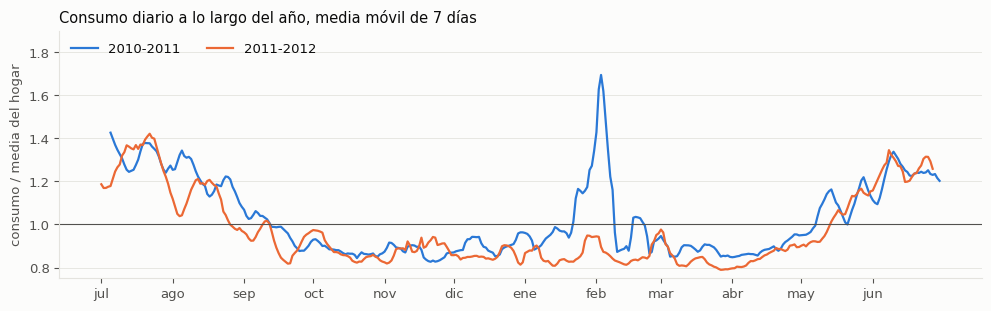

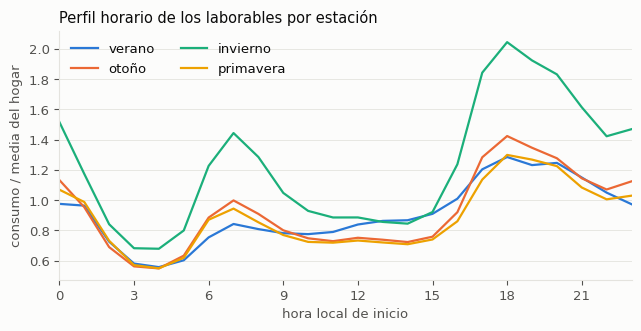

In [21]:
day_level = days_rel.loc[days_rel["fecha_local"].gt(first_day)].groupby("fecha_local")["consumo_rel"].mean()
season_year = np.where(day_level.index < pd.Timestamp("2011-07-01"), "2010-2011", "2011-2012")
monthly = day_level.groupby([season_year, day_level.index.month]).mean().unstack()
monthly = monthly[[7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]].rename(columns=lambda m: MONTHS[m - 1])
print("Consumo diario medio de cada mes, respecto a la media del hogar:")
display(monthly.round(2))
both_years = monthly.mean()
print(f"Mes de más consumo / mes de menos consumo (media de los dos años): {both_years.max() / both_years.min():.2f}")

smooth = day_level.rolling(7, center=True).mean()
first_year = smooth.loc[:"2011-06-30"]
second_year = smooth.loc["2011-07-01":]
second_year.index = second_year.index - pd.DateOffset(years=1)
second_year = second_year.groupby(level=0).mean()  # el 29-feb-2012 cae sobre el 28-feb
print(f"Correlación entre los dos años de la media móvil de 7 días: {first_year.corr(second_year):.2f}")

weather_days = weather.groupby(weather_day)["temperature_2m"].agg(["mean", "max"])
summer_days = weather_days.loc[weather_days.index.month.isin([12, 1, 2])
                               & (weather_days.index > first_day) & (weather_days.index <= last_day)]
summer_label = [f"{y}-{y + 1}" for y in summer_days.index.year - (summer_days.index.month < 12)]
print("\nTemperatura de los dos veranos (diciembre a febrero):")
display(summer_days.groupby(summer_label).agg(**{
    "temperatura media (°C)": ("mean", "mean"),
    "días de 30 °C o más": ("max", lambda s: int(s.ge(30).sum())),
}).round(1))

season_level = train.groupby(["customer", "estacion"], observed=True)["consumo_rel"].mean().unstack()
winter_summer = season_level["invierno"] / season_level["verano"]
print("\nConsumo de invierno / consumo de verano, en cada hogar:")
display(winter_summer.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_frame("cociente").T)
summer_peak = winter_summer.lt(1)
print("Hogares que consumen más en verano que en invierno:", int(summer_peak.sum()),
      "| con CL:", int(customers.loc[summer_peak, "has_cl"].sum()),
      "| hogares con CL en total:", int(customers["has_cl"].sum()))
print("Consumo medio por hora de los hogares con CL, por estación (kWh):")
display(train.loc[train["has_cl"]].groupby("estacion", observed=True)[["gc_kwh", "cl_kwh"]].mean().round(3).T)

season_profiles = (train.loc[train["tipo_dia"].eq("laborable")]
                   .groupby(["estacion", "hora_local"], observed=True)["consumo_rel"].mean().unstack())
print("\nPerfil horario de los laborables en cada estación (consumo / media del hogar):")
display(season_profiles.round(2))

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(first_year.index, first_year.to_numpy(), color=BLUE, label="2010-2011")
ax.plot(second_year.index, second_year.to_numpy(), color=ORANGE, label="2011-2012")
ax.axhline(1, color=TEXT_SECONDARY, linewidth=0.8)
month_ticks = pd.date_range("2010-07-01", "2011-06-01", freq="MS")
ax.set_xticks(month_ticks)
ax.set_xticklabels([MONTHS[t.month - 1] for t in month_ticks])
ax.set_ylabel("consumo / media del hogar")
ax.set_title("Consumo diario a lo largo del año, media móvil de 7 días", loc="left")
ax.set_ylim(0.75, 1.9)
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for season, color in zip(season_profiles.index, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(season_profiles.columns, season_profiles.loc[season].to_numpy(), color=color, label=season)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 23)
ax.set_xlabel("hora local de inicio")
ax.set_ylabel("consumo / media del hogar")
ax.set_title("Perfil horario de los laborables por estación", loc="left")
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

**Resultado.** El consumo tiene un ciclo anual marcado por el invierno. Julio es el mes de más consumo, entre un 30 y un 33 % por encima de la media del hogar, y de octubre a abril el consumo se queda entre un 10 y un 17 % por debajo, salvo en el verano de 2011. Entre el mes de más consumo y el de menos hay un factor de 1,53. El invierno se repite los dos años; el verano depende de la temperatura. El de 2010-2011 tuvo 21 días de 30 °C o más, y en enero y febrero se consumió un 1 % y un 10 % por encima de la media. El de 2011-2012 fue más fresco (2,3 °C menos de media y solo 3 días de 30 °C), y esos meses quedaron un 13 y un 14 % por debajo. La correlación entre los dos años de la media móvil de 7 días es 0,77.

No todos los hogares siguen el ciclo. En la mediana, un hogar consume en invierno un 31 % más que en verano, y en un 5 % de los hogares el consumo de invierno es más de 2,5 veces el de verano. Pero 55 hogares consumen más en verano que en invierno. Entre ellos hay menos hogares con carga controlada (19, un 35 %, frente al 45 % del total), lo que cuadra con que el `CL` consume casi el doble en invierno que en verano (0,30 frente a 0,16 kWh por hora).

La forma del perfil también cambia. En invierno el pico de la tarde llega a 2,04 veces la media del hogar, frente a 1,29 en verano, y hay un pico de mañana a las 07:00 (1,44) que en verano casi desaparece (0,84). En verano el consumo es mayor a mediodía y a primera hora de la tarde (de 0,84 a 0,91 entre las 12:00 y las 15:00, frente a entre 0,71 y 0,76 en otoño y primavera). Otoño y primavera tienen perfiles casi iguales. El pico de la tarde cae a las 18:00 en las cuatro estaciones.

### 3.4 ¿El consumo sigue la hora local?

Las variables de calendario están en hora local (sección 0.2). Si la rutina de los hogares sigue el reloj, al cambiar al horario de verano o volver de él el perfil debería desplazarse una hora en UTC y quedarse igual en hora local. Para cada cambio se compara la forma del perfil de los laborables de las dos semanas anteriores con la de las dos semanas posteriores, contando las horas primero en hora local y después en UTC.

In [22]:
weekdays = train.loc[train["tipo_dia"].eq("laborable"), ["fecha_local", "hora_local", "timestamp_utc", "consumo_rel"]]
weekdays = weekdays.assign(hora_utc=(weekdays["timestamp_utc"] - pd.Timedelta(hours=1)).dt.hour)
rows = []
for day, reason in irregular.loc[irregular["horas"].isin([23, 25]), "motivo"].items():
    before = weekdays["fecha_local"].between(day - pd.Timedelta(days=14), day - pd.Timedelta(days=1))
    after = weekdays["fecha_local"].between(day + pd.Timedelta(days=1), day + pd.Timedelta(days=14))
    row = {"cambio": f"{day:%d-%m-%Y}, {reason}"}
    for column, label in [("hora_local", "contando en hora local"), ("hora_utc", "contando en UTC")]:
        row[label] = shape_gap(weekdays.loc[before].groupby(column)["consumo_rel"].mean(),
                               weekdays.loc[after].groupby(column)["consumo_rel"].mean())
    rows.append(row)
del weekdays
print("Diferencia de forma (%) entre el perfil de las dos semanas anteriores y el de las dos posteriores:")
pd.DataFrame(rows).set_index("cambio").round(1)

Diferencia de forma (%) entre el perfil de las dos semanas anteriores y el de las dos posteriores:


,contando en hora local,contando en UTC
cambio,,
"03-10-2010, inicio del horario de verano",8.3,8.9
"03-04-2011, fin del horario de verano",7.4,10.6
"02-10-2011, inicio del horario de verano",6.9,8.3
"01-04-2012, fin del horario de verano",6.4,9.8


**Resultado.** En los cuatro cambios de horario el perfil de después se parece más al de antes si las horas se cuentan en hora local (diferencias del 6,4 al 8,3 %) que si se cuentan en UTC (del 8,3 al 10,6 %). La diferencia entre las dos formas de contar es clara en abril y menor en octubre, probablemente porque en octubre el consumo ya está bajando con el fin del invierno y la forma cambia de todos modos (sección 3.3). La rutina de los hogares sigue el reloj. Si las variables de hora se calcularan en UTC, el mismo hábito caería en una hora distinta durante medio año. La excepción es la carga controlada: en casi la mitad de los hogares que la tienen, su temporizador sigue la hora estándar todo el año (sección 4.5).

## 4. Dependencia temporal

Los modelos del Plan usan el consumo de las horas anteriores (LightGBM con retardos, LSTM) y se comparan con dos referencias: la persistencia estacional y la media estacional. Este bloque mide cuánto se parece el consumo a su propio pasado: qué retardos se parecen más a la hora que se quiere predecir, cuánto duran las desviaciones respecto al calendario y a partir de qué horizonte el pasado reciente deja de ayudar.

Todo se calcula hogar por hogar y se resume con la mediana de los 300 hogares, que no se deja arrastrar por los pocos que tienen periodos de casa vacía (sección 2.5). Los retardos se cuentan en horas reales. En los cuatro días de cambio de horario, el retardo de 24 horas cae una hora antes o después en el reloj, un efecto que se puede despreciar.

### 4.1 Autocorrelación del consumo horario

La autocorrelación en el retardo *k* es la correlación entre el consumo de cada hora y el de *k* horas antes. Se calcula para el consumo y para su **desviación respecto al calendario del hogar**: la diferencia entre el consumo de cada hora y la media de ese hogar en la misma estación, tipo de día y hora (las combinaciones de la sección 1.5). La desviación es lo que el calendario no explica, y su autocorrelación indica cuánto pueden aportar los retardos además del calendario.

Autocorrelación en algunos retardos (horas), entre los 300 hogares:


1      2      3      6      12     24     48     144    168    192    336
consumo                           p10      0.368  0.079  0.006 -0.064 -0.096  0.337  0.289  0.250  0.268  0.246  0.233
                                  mediana  0.594  0.329  0.209  0.055  0.032  0.524  0.469  0.422  0.444  0.422  0.416
                                  p90      0.760  0.566  0.425  0.220  0.235  0.727  0.695  0.664  0.675  0.651  0.649
desviación respecto al calendario p10      0.270  0.090  0.048  0.025  0.023  0.119  0.089  0.052  0.062  0.038  0.036
                                  mediana  0.504  0.276  0.187  0.110  0.080  0.277  0.211  0.132  0.149  0.109  0.112
                                  p90      0.712  0.503  0.383  0.231  0.179  0.466  0.405  0.313  0.328  0.289  0.269

Parte de la varianza horaria de cada hogar que explica su calendario:


,mean,std,min,10%,25%,50%,75%,90%,max
R²,0.358,0.143,0.084,0.189,0.255,0.334,0.466,0.568,0.819


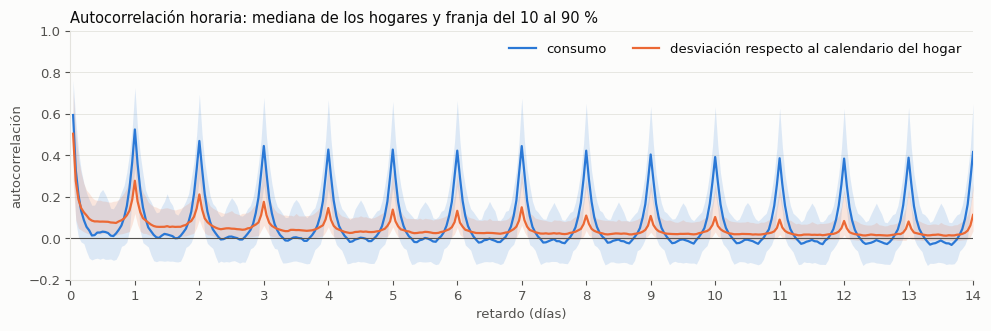

In [23]:
utc_hours = train["timestamp_utc"].dt.tz_convert(None).to_numpy().astype("int64")
order = np.lexsort((utc_hours, train["customer"].to_numpy()))
customer_ids = np.unique(train["customer"].to_numpy())
n_hours = len(train) // len(customer_ids)


def by_household(values):
    """Matriz hogares × horas, en orden cronológico, de una columna de train (o de un array alineado con train)."""
    values = train[values].to_numpy() if isinstance(values, str) else np.asarray(values)
    return values[order].reshape(len(customer_ids), n_hours)


hour_grid = by_household(utc_hours)
if not ((by_household("customer") == customer_ids[:, None]).all() and (hour_grid == hour_grid[0]).all()):
    raise ValueError("Los hogares no tienen todos las mismas horas")
del hour_grid, utc_hours
hour_calendar = (train.iloc[order[:n_hours]][["timestamp_utc", "fecha_local", "hora_local", "dia_semana", "festivo"]]
                 .reset_index(drop=True))
hour_calendar["hora_utc"] = (hour_calendar["timestamp_utc"] - pd.Timedelta(hours=1)).dt.hour
hourly = by_household("demand_kwh")
calendar_mean = train.groupby(["customer", "estacion", "tipo_dia", "hora_local"], observed=True)["demand_kwh"].transform("mean")
hourly_dev = hourly - by_household(calendar_mean)
del calendar_mean


def autocorrelation(matrix, lags):
    """Autocorrelación de cada fila (un hogar) en los retardos indicados: matriz retardos × hogares."""
    z = (matrix - matrix.mean(axis=1, keepdims=True)) / matrix.std(axis=1, keepdims=True)
    return np.array([(z[:, lag:] * z[:, :-lag]).mean(axis=1) for lag in lags])


def spread(values, labels):
    """Percentiles 10, 50 y 90 entre hogares de cada fila de values (retardos × hogares)."""
    return pd.DataFrame({"p10": np.percentile(values, 10, axis=1), "mediana": np.median(values, axis=1),
                         "p90": np.percentile(values, 90, axis=1)}, index=labels).T


HOUR_LAGS = np.arange(1, 24 * 14 + 1)
acf_hourly = autocorrelation(hourly, HOUR_LAGS)
acf_hourly_dev = autocorrelation(hourly_dev, HOUR_LAGS)
SHOW_HOURS = [1, 2, 3, 6, 12, 24, 48, 144, 168, 192, 336]
print("Autocorrelación en algunos retardos (horas), entre los 300 hogares:")
display(pd.concat({
    "consumo": spread(acf_hourly[np.array(SHOW_HOURS) - 1], SHOW_HOURS),
    "desviación respecto al calendario": spread(acf_hourly_dev[np.array(SHOW_HOURS) - 1], SHOW_HOURS),
}).round(3))
explained = pd.Series(1 - hourly_dev.var(axis=1) / hourly.var(axis=1), index=customer_ids)
print("Parte de la varianza horaria de cada hogar que explica su calendario:")
display(explained.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).drop("count").round(3).to_frame("R²").T)

fig, ax = plt.subplots(figsize=(10, 3.4))
for values, color, label in [(acf_hourly, BLUE, "consumo"),
                             (acf_hourly_dev, ORANGE, "desviación respecto al calendario del hogar")]:
    ax.fill_between(HOUR_LAGS, np.percentile(values, 10, axis=1), np.percentile(values, 90, axis=1),
                    color=color, alpha=0.15, linewidth=0)
    ax.plot(HOUR_LAGS, np.median(values, axis=1), color=color, label=label)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_xticks(range(0, 24 * 14 + 1, 24))
ax.set_xticklabels(range(0, 15))
ax.set_xlim(0, 24 * 14)
ax.set_ylim(-0.2, 1)
ax.set_xlabel("retardo (días)")
ax.set_ylabel("autocorrelación")
ax.set_title("Autocorrelación horaria: mediana de los hogares y franja del 10 al 90 %", loc="left")
ax.legend(loc="upper right", ncols=2)
fig.tight_layout()
plt.show()

**Resultado.** El consumo se parece sobre todo al de la hora anterior y al de la misma hora de días anteriores. La autocorrelación mediana es de 0,59 con la hora anterior, cae casi a 0 a las 6 y a las 12 horas y vuelve a subir cada 24 horas: 0,52 con el día anterior, 0,47 con dos días antes y unos 0,42 a partir del sexto día. El pico semanal es pequeño: 0,44 a 168 horas frente a 0,42 a 144 y a 192. Un día se parece casi lo mismo al día anterior que al mismo día de la semana anterior, y algo más al día anterior.

El calendario de cada hogar (estación, tipo de día y hora) explica una mediana del 33 % de la varianza horaria, con hogares entre el 19 y el 57 % (percentiles 10 y 90). Como se ajusta con los mismos dos años, es un máximo. Lo que queda tiene memoria propia: la desviación respecto al calendario se correlaciona 0,50 con la de la hora anterior y 0,28 con la del día anterior, y sigue en 0,11 dos semanas después. Los retardos aportan información que el calendario no tiene, sobre todo los de 1 a 3 horas y los de 24 y 48 horas.

### 4.2 Persistencia de un día y de una semana

La forma más simple de pronosticar una hora es copiar horas anteriores. Se comparan cuatro referencias de este tipo, que son las candidatas a persistencia estacional y media estacional del Plan:

- **día anterior**: la misma hora del día anterior (retardo de 24 horas);
- **semana anterior**: la misma hora de la semana anterior (168 horas);
- **media de 7 días**: la media de la misma hora en los 7 días anteriores;
- **media de 4 semanas**: la media de la misma hora y el mismo día de la semana en las 4 semanas anteriores.

Para cada hogar se calcula el error absoluto medio y se divide por su consumo medio, para poder comparar hogares. Las cuatro se evalúan en las mismas horas, desde el 29 de julio de 2010, el primer día con 4 semanas de historia. No es una evaluación de modelos: solo mide cuánto se repite el consumo de un día a otro y de una semana a otra.

In [24]:
evaluated = np.arange(24 * 7 * 4, n_hours)
actual = hourly[:, evaluated]
household_mean = hourly.mean(axis=1)
references = {
    "día anterior": lambda t: hourly[:, t - 24],
    "semana anterior": lambda t: hourly[:, t - 168],
    "media de 7 días": lambda t: sum(hourly[:, t - 24 * k] for k in range(1, 8)) / 7,
    "media de 4 semanas": lambda t: sum(hourly[:, t - 168 * k] for k in range(1, 5)) / 4,
}
day_class = np.where(hour_calendar["festivo"].to_numpy(), "festivo",
                     np.array(DAY_SHORT)[hour_calendar["dia_semana"].to_numpy()])[evaluated]
reference_mae, mae_by_day = {}, {}
for name, predict in references.items():
    error = np.abs(predict(evaluated) - actual) / household_mean[:, None]
    reference_mae[name] = error.mean(axis=1)
    mae_by_day[name] = {c: np.median(error[:, day_class == c].mean(axis=1)) for c in DAY_SHORT + ["festivo"]}
    del error
del actual
reference_mae = pd.DataFrame(reference_mae, index=customer_ids)

print("Error absoluto medio / consumo medio del hogar, entre los 300 hogares:")
display(reference_mae.describe(percentiles=[0.25, 0.5, 0.75]).loc[["25%", "50%", "75%"]].round(3))
print("Hogares en que la semana anterior acierta más que el día anterior:",
      int((reference_mae["semana anterior"] < reference_mae["día anterior"]).sum()))
print("Hogares en que la media de 7 días acierta más que las dos persistencias:",
      int((reference_mae["media de 7 días"] < reference_mae[["día anterior", "semana anterior"]].min(axis=1)).sum()))
print("\nMediana del error relativo según el día que se pronostica:")
display(pd.DataFrame(mae_by_day).round(3))

mase_scale = pd.Series({
    f"persistencia de {m} h": np.median(np.abs(hourly[:, m:] - hourly[:, :-m]).mean(axis=1) / household_mean)
    for m in (24, 168)
})
print("Escala del MASE: error de la persistencia en todas las horas de los dos años (mediana, relativo al consumo medio):")
mase_scale.round(3).to_frame("error relativo").T

Error absoluto medio / consumo medio del hogar, entre los 300 hogares:


,día anterior,semana anterior,media de 7 días,media de 4 semanas
25%,0.426,0.455,0.372,0.409
50%,0.501,0.540,0.437,0.476
75%,0.613,0.656,0.538,0.582


Hogares en que la semana anterior acierta más que el día anterior: 41
Hogares en que la media de 7 días acierta más que las dos persistencias: 292

Mediana del error relativo según el día que se pronostica:


,día anterior,semana anterior,media de 7 días,media de 4 semanas
lun,0.545,0.505,0.423,0.456
mar,0.475,0.506,0.425,0.461
mié,0.461,0.510,0.421,0.457
jue,0.464,0.513,0.420,0.456
vie,0.474,0.522,0.432,0.463
sáb,0.543,0.603,0.478,0.527
dom,0.559,0.597,0.479,0.521
festivo,0.528,0.572,0.461,0.506


Escala del MASE: error de la persistencia en todas las horas de los dos años (mediana, relativo al consumo medio):


,persistencia de 24 h,persistencia de 168 h
error relativo,0.508,0.545


**Resultado.** Copiar el día anterior tiene un error mediano del 50 % del consumo medio del hogar, y copiar la semana anterior, del 54 %: la persistencia de 24 horas acierta más en 259 de los 300 hogares. La semana anterior solo gana los lunes (0,505 frente a 0,545), porque el día anterior a un lunes es un domingo. En sábados, domingos y festivos las dos persistencias tienen más error (de 0,53 a 0,60) que en los laborables (de 0,46 a 0,52).

Promediar varios días reduce bastante el error. La media de la misma hora en los 7 días anteriores tiene un error mediano del 44 % y acierta más que las dos persistencias en 292 hogares; la media de 4 semanas queda en el 48 %. Al promediar se elimina más ruido de cada hora del que se pierde por mezclar laborables y fines de semana, aunque sábados y domingos siguen siendo los días con más error.

Para el MASE, la escala con la persistencia de 24 horas es un 7 % menor que con la de 168 horas (0,508 frente a 0,545 del consumo medio).

### 4.3 Cuánto duran las desviaciones

Las desviaciones horarias mezclan el ruido de cada hora con cambios que duran días, como una ola de calor, una visita o unas vacaciones. Para ver estos últimos se repite el análisis con la energía diaria: la desviación de cada día respecto a la media del hogar en la misma estación y tipo de día, y su autocorrelación con retardos de 1 a 60 días. No se usa el 1 de julio de 2010, que solo tiene 15 horas.

Autocorrelación de la desviación diaria en algunos retardos (días), entre los 300 hogares:


,1,2,3,7,14,21,28,42,60
p10,0.351,0.224,0.147,0.083,0.022,-0.025,-0.043,-0.069,-0.080
mediana,0.551,0.405,0.316,0.220,0.156,0.078,0.055,0.017,-0.003
p90,0.712,0.609,0.564,0.448,0.375,0.275,0.257,0.212,0.143


Primer retardo con autocorrelación mediana por debajo de 0.2: 8 días
Primer retardo con autocorrelación mediana por debajo de 0.1: 18 días


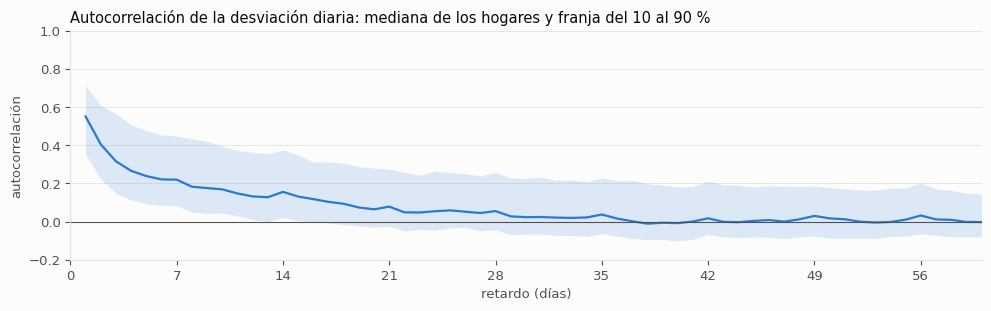

In [25]:
day_matrix = daily.unstack("fecha_local").drop(columns=first_day)
day_types = days.set_index("fecha_local").loc[day_matrix.columns, ["estacion", "tipo_dia"]]
day_group = (day_types["estacion"].astype(str) + " / " + day_types["tipo_dia"].astype(str)).to_numpy()
day_dev = day_matrix - day_matrix.T.groupby(day_group).transform("mean").T

DAY_LAGS = np.arange(1, 61)
acf_daily_dev = autocorrelation(day_dev.to_numpy(), DAY_LAGS)
SHOW_DAYS = [1, 2, 3, 7, 14, 21, 28, 42, 60]
print("Autocorrelación de la desviación diaria en algunos retardos (días), entre los 300 hogares:")
display(spread(acf_daily_dev[np.array(SHOW_DAYS) - 1], SHOW_DAYS).round(3))
median_daily_acf = pd.Series(np.median(acf_daily_dev, axis=1), index=DAY_LAGS)
for level in (0.2, 0.1):
    print(f"Primer retardo con autocorrelación mediana por debajo de {level}: {median_daily_acf.lt(level).idxmax()} días")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(DAY_LAGS, np.percentile(acf_daily_dev, 10, axis=1), np.percentile(acf_daily_dev, 90, axis=1),
                color=BLUE, alpha=0.15, linewidth=0)
ax.plot(DAY_LAGS, median_daily_acf.to_numpy(), color=BLUE)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_xticks(range(0, 61, 7))
ax.set_xlim(0, 60)
ax.set_ylim(-0.2, 1)
ax.set_xlabel("retardo (días)")
ax.set_ylabel("autocorrelación")
ax.set_title("Autocorrelación de la desviación diaria: mediana de los hogares y franja del 10 al 90 %", loc="left")
fig.tight_layout()
plt.show()

**Resultado.** Las desviaciones de la energía diaria duran días. La autocorrelación mediana es de 0,55 con el día anterior, 0,22 a una semana y 0,16 a dos semanas; baja de 0,2 a los 8 días y de 0,1 a los 18, y a partir de unas 6 semanas es prácticamente 0 (0,02 a 42 días). En algunos hogares duran bastante más: el percentil 90 sigue en 0,26 a las 4 semanas, seguramente por las casas vacías y los cambios de nivel de las secciones 2.5 y 2.6. Para horizontes de días, el pasado reciente sigue aportando información además del calendario; a partir de unas 3 a 6 semanas, casi ninguna.

### 4.4 Horizontes de semanas y meses

Para los horizontes largos el Plan prevé un modelo de energía diaria o semanal. Aquí se compara, al pronosticar la energía de una semana, el pasado reciente con el mismo periodo del año anterior:

- **semana reciente**: la energía de los 7 días que terminan el día del último dato. El horizonte *h* es el número de días entre ese día y el inicio de la semana pronosticada;
- **año anterior**: la energía de la misma semana del año anterior, 364 días antes, para que coincidan los días de la semana. No depende del horizonte.

Se pronostican las semanas que empiezan entre el 1 de julio de 2011 y el 24 de junio de 2012, porque el año anterior necesita un año de historia. El error de cada hogar se divide por su energía media semanal.

Error de la semana reciente según el horizonte (días), entre los 300 hogares:


,1,7,14,28,42,56,84,112,182
p25,0.106,0.128,0.140,0.151,0.166,0.181,0.199,0.206,0.229
mediana,0.139,0.166,0.182,0.212,0.237,0.257,0.287,0.294,0.317
p75,0.176,0.216,0.246,0.282,0.321,0.361,0.404,0.436,0.457


Error del año anterior: p25 0.178 | mediana 0.237 | p75 0.310
Primer horizonte en que la semana reciente tiene más error que el año anterior: 43 días
Hogares en que el año anterior acierta más que la semana reciente a 14 días: 79
Hogares en que el año anterior acierta más que la semana reciente a 28 días: 138
Hogares en que el año anterior acierta más que la semana reciente a 56 días: 186


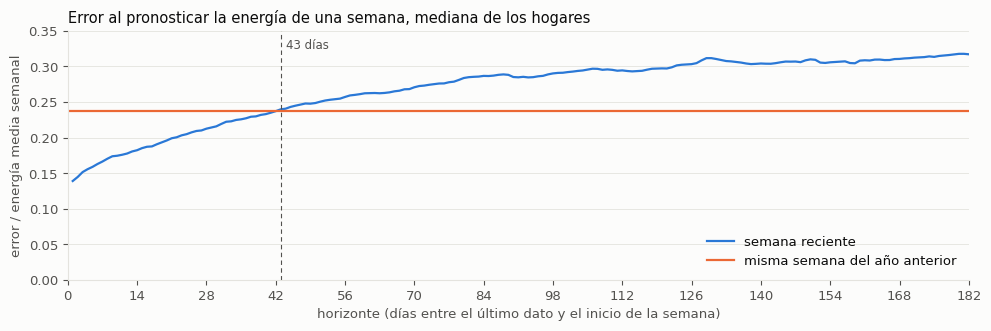

In [26]:
day_values = day_matrix.to_numpy()
week_energy = np.lib.stride_tricks.sliding_window_view(day_values, 7, axis=1).sum(axis=-1)  # semana que empieza cada día
week_mean = day_values.mean(axis=1) * 7
targets = np.arange(day_matrix.columns.get_loc(pd.Timestamp("2011-07-01")), week_energy.shape[1])
actual_week = week_energy[:, targets]


def week_error(forecast):
    """Error absoluto medio de cada hogar, dividido por su energía media semanal."""
    return np.abs(forecast - actual_week).mean(axis=1) / week_mean


HORIZONS = np.arange(1, 183)
recent_error = np.array([week_error(week_energy[:, targets - h - 6]) for h in HORIZONS])  # horizontes × hogares
last_year_error = week_error(week_energy[:, targets - 364])
SHOW_HORIZONS = [1, 7, 14, 28, 42, 56, 84, 112, 182]
print("Error de la semana reciente según el horizonte (días), entre los 300 hogares:")
display(pd.DataFrame({h: np.percentile(recent_error[h - 1], [25, 50, 75]) for h in SHOW_HORIZONS},
                     index=["p25", "mediana", "p75"]).round(3))
print("Error del año anterior: p25 {:.3f} | mediana {:.3f} | p75 {:.3f}".format(*np.percentile(last_year_error, [25, 50, 75])))
median_recent = np.median(recent_error, axis=1)
crossing = int(HORIZONS[median_recent > np.median(last_year_error)][0])
print(f"Primer horizonte en que la semana reciente tiene más error que el año anterior: {crossing} días")
for h in (14, 28, 56):
    print(f"Hogares en que el año anterior acierta más que la semana reciente a {h} días:",
          int((last_year_error < recent_error[h - 1]).sum()))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(HORIZONS, median_recent, color=BLUE, label="semana reciente")
ax.axhline(np.median(last_year_error), color=ORANGE, label="misma semana del año anterior")
ax.axvline(crossing, color=TEXT_SECONDARY, linewidth=0.8, linestyle=(0, (4, 3)))
ax.annotate(f"{crossing} días", (crossing, 0.33), xytext=(4, 0), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=8.5, va="center")
ax.set_xticks(range(0, 183, 14))
ax.set_xlim(0, 182)
ax.set_ylim(0, 0.35)
ax.set_xlabel("horizonte (días entre el último dato y el inicio de la semana)")
ax.set_ylabel("error / energía media semanal")
ax.set_title("Error al pronosticar la energía de una semana, mediana de los hogares", loc="left")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Resultado.** Con el último dato el día antes de que empiece la semana, su energía se pronostica con un error mediano del 14 % de una semana normal del hogar. El error crece con el horizonte: 17 % a una semana, 21 % a cuatro, 26 % a ocho y 32 % a seis meses. La misma semana del año anterior tiene un error del 24 %, y desde los 43 días (unas 6 semanas) acierta más que la semana reciente. Es el mismo plazo en el que la autocorrelación de las desviaciones diarias llega a 0 (sección 4.3). El cruce no llega a la vez en todos los hogares: a 28 días el año anterior ya acierta más en 138 hogares, y a 56 días, en 186.

Es coherente con lo que propone el Plan: para semanas y meses, un modelo basado en el calendario y la estacionalidad. Con dos años de datos, "el año anterior" es un solo año, así que su error incluye todo lo que cambió de un año a otro: los cambios de nivel de la sección 2.6 y el verano más fresco de 2011-2012 (sección 3.3).

### 4.5 Regularidad de la carga controlada

La sección 2.4 mostró que el `CL` tiene un horario propio, y `docs/data/gaps.md` (G13) deja para este análisis decidir si su patrón es lo bastante predecible como para modelarlo aparte. Aquí se mide, en los 136 hogares con carga controlada, cuánto se repite el `CL` de un día a otro, separando **cuándo** se consume de **cuánto** se consume, y se compara con el `GC` de los mismos hogares:

- **horas habituales**: el menor número de horas del día que reúne el 80 % de la energía de `CL` del hogar, según su perfil medio por hora local;
- **parte del día en las horas habituales**: qué fracción del `CL` de cada día cae en esas horas (mediana de los días con al menos 0,05 kWh de `CL`);
- **días sin CL**: días con menos de 0,05 kWh de `CL`;
- **variación del total diario**: coeficiente de variación de la energía diaria;
- **autocorrelación a 24 h** y **error de la persistencia de 24 h**, como en las secciones 4.1 y 4.2.

Hogares con CL: 136


,min,10%,25%,50%,75%,90%,max
horas habituales,1.00,3.00,3.00,5.00,8.00,11.00,15.00
parte del día en las horas habituales,0.80,0.83,0.85,0.93,1.00,1.00,1.00
días sin CL (%),0.00,0.00,0.00,3.70,38.70,66.44,96.58
"variación del total diario, CL",0.23,0.31,0.39,0.53,1.11,1.69,5.90
"variación del total diario, GC",0.18,0.26,0.31,0.39,0.49,0.58,1.11
"autocorrelación a 24 h, CL",0.04,0.21,0.44,0.69,0.83,0.88,0.96
"autocorrelación a 24 h, GC",0.16,0.33,0.40,0.48,0.56,0.67,0.86
"error de la persistencia de 24 h, CL",0.24,0.41,0.51,0.76,1.16,1.48,1.91
"error de la persistencia de 24 h, GC",0.27,0.35,0.42,0.49,0.57,0.66,0.77


Días sin CL por estación (% de los días, media de los hogares con CL):


,verano,otoño,invierno,primavera
%,30.0,20.2,9.3,23.3


Hogares con CL con más del 30 % de días sin CL: 42


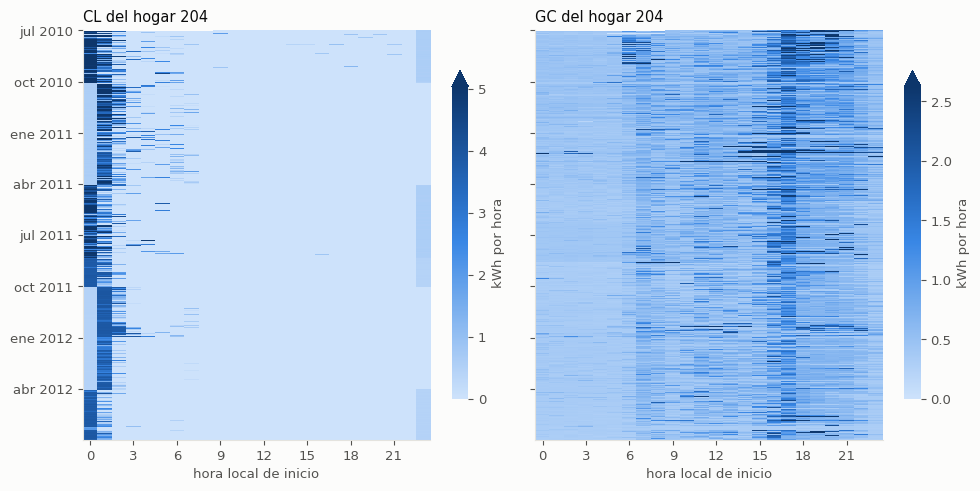

In [27]:
cl_rows = np.isin(customer_ids, customers.index[customers["has_cl"]])
cl_ids = customer_ids[cl_rows]
gc_hourly = by_household("gc_kwh")[cl_rows]
cl_hourly = by_household("cl_kwh")[cl_rows]
local_hour = hour_calendar["hora_local"].to_numpy()
hour_day = hour_calendar["fecha_local"].to_numpy()
full_day = hour_calendar["fecha_local"].gt(first_day).to_numpy()


def daily_totals(matrix):
    """Energía diaria de cada hogar (días × hogares), sin el primer día incompleto."""
    return pd.DataFrame(matrix[:, full_day].T, index=hour_day[full_day]).groupby(level=0).sum()


cl_profile = pd.DataFrame(cl_hourly.T).groupby(local_hour).mean().T.to_numpy()  # hogares × hora local
ranked = -np.sort(-cl_profile, axis=1)
usual_hours = (np.cumsum(ranked, axis=1) / ranked.sum(axis=1, keepdims=True) < 0.8).sum(axis=1) + 1
in_usual = cl_profile >= ranked[np.arange(len(ranked)), usual_hours - 1][:, None]

cl_day = daily_totals(cl_hourly)
cl_day_usual = daily_totals(cl_hourly * in_usual[:, local_hour])
gc_day = daily_totals(gc_hourly)
cl_active = cl_day.ge(0.05)
regularity = pd.DataFrame({
    "horas habituales": usual_hours,
    "parte del día en las horas habituales": (cl_day_usual / cl_day).where(cl_active).median().to_numpy(),
    "días sin CL (%)": 100 * (~cl_active).mean().to_numpy(),
    "variación del total diario, CL": (cl_day.std() / cl_day.mean()).to_numpy(),
    "variación del total diario, GC": (gc_day.std() / gc_day.mean()).to_numpy(),
    "autocorrelación a 24 h, CL": autocorrelation(cl_hourly, [24])[0],
    "autocorrelación a 24 h, GC": autocorrelation(gc_hourly, [24])[0],
    "error de la persistencia de 24 h, CL":
        np.abs(cl_hourly[:, 24:] - cl_hourly[:, :-24]).mean(axis=1) / cl_hourly.mean(axis=1),
    "error de la persistencia de 24 h, GC":
        np.abs(gc_hourly[:, 24:] - gc_hourly[:, :-24]).mean(axis=1) / gc_hourly.mean(axis=1),
}, index=cl_ids)
print(f"Hogares con CL: {len(cl_ids)}")
display(regularity.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).drop(index=["count", "mean", "std"]).T.round(2))

season_of_day = days.set_index("fecha_local")["estacion"].reindex(cl_day.index).astype(str).to_numpy()
print("Días sin CL por estación (% de los días, media de los hogares con CL):")
display((100 * (~cl_active).groupby(season_of_day).mean().mean(axis=1))
        .reindex(["verano", "otoño", "invierno", "primavera"]).round(1).to_frame("%").T)
print("Hogares con CL con más del 30 % de días sin CL:", int(regularity["días sin CL (%)"].gt(30).sum()))

usual_share = regularity["parte del día en las horas habituales"]
example = (usual_share[regularity["días sin CL (%)"].lt(5)] - usual_share.median()).abs().idxmin()
row = int(np.flatnonzero(cl_ids == example)[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, matrix, label in [(axes[0], cl_hourly, "CL"), (axes[1], gc_hourly, "GC")]:
    grid = (pd.DataFrame({"dia": hour_day, "hora": local_hour, "kwh": matrix[row]})
            .pivot_table(index="dia", columns="hora", values="kwh", aggfunc="mean"))
    image = ax.imshow(grid.to_numpy(), aspect="auto", cmap=BLUE_RAMP, vmin=0,
                      vmax=np.nanpercentile(grid.to_numpy(), 99), interpolation="nearest")
    ax.grid(False)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hora local de inicio")
    ax.set_title(f"{label} del hogar {example}", loc="left")
    colorbar = fig.colorbar(image, ax=ax, shrink=0.8, extend="max")
    colorbar.set_label("kWh por hora")
    colorbar.outline.set_visible(False)
quarter_starts = [i for i, d in enumerate(grid.index) if d.day == 1 and d.month in (1, 4, 7, 10)]
axes[0].set_yticks(quarter_starts)
axes[0].set_yticklabels([f"{MONTHS[grid.index[i].month - 1]} {grid.index[i].year}" for i in quarter_starts])
fig.tight_layout()
plt.show()

**Resultado.** El `CL` es muy regular en **cuándo** se consume y poco en **cuánto**:

- **Cuándo.** En la mediana, 5 horas reúnen el 80 % del `CL` del hogar (entre 3 y 11 en los percentiles 10 y 90), y cada día el 93 % del `CL` cae en esas horas. Su autocorrelación a 24 horas es mayor que la del `GC` (0,69 frente a 0,48): de un día a otro, el `CL` se enciende a las mismas horas.
- **Cuánto.** El total diario varía más que el del `GC` (coeficiente de variación de 0,53 frente a 0,39), y copiar el `CL` del día anterior tiene más error relativo (0,76 frente a 0,49). Además hay muchos días sin `CL`. En la mediana de los hogares son solo el 4 %, pero en 42 de los 136 hogares pasan del 30 %, y en conjunto son el 30 % de los días de verano frente al 9 % de los de invierno: en esos hogares el `CL` se usa poco o nada en verano.

El mapa de calor del hogar 204 muestra las dos cosas. El `CL` se enciende cada noche hacia la medianoche durante una o dos horas, con más energía en invierno que en verano, mientras que el `GC` se reparte por todo el día y varía más de un día a otro. Muestra además algo inesperado: el `CL` empieza a las 00:00 en invierno y a la 01:00 cuando rige el horario de verano, de octubre a abril. Su temporizador no cambia de hora. Se comprueba en todos los hogares.

Si el temporizador del `CL` sigue la hora estándar de Sídney (UTC+10) y no la hora local, al cambiar el horario su perfil debería quedarse igual en UTC y moverse una hora en hora local, al revés que el consumo general (sección 3.4). Se repite la prueba de la sección 3.4 por separado para el `CL` y el `GC` de los hogares con carga controlada. Después se cuenta en cuántos hogares cambia la hora local del pico medio cuando rige el horario de verano.

In [28]:
utc_hour = hour_calendar["hora_utc"].to_numpy()
summer_time = (local_hour - utc_hour) % 24 == 11
weekday_hours = (~hour_calendar["festivo"] & hour_calendar["dia_semana"].lt(5)).to_numpy()
cl_mean_hour, gc_mean_hour = cl_hourly.mean(axis=0), gc_hourly.mean(axis=0)
rows = []
for day, reason in irregular.loc[irregular["horas"].isin([23, 25]), "motivo"].items():
    before = weekday_hours & hour_calendar["fecha_local"].between(day - pd.Timedelta(days=14),
                                                                  day - pd.Timedelta(days=1)).to_numpy()
    after = weekday_hours & hour_calendar["fecha_local"].between(day + pd.Timedelta(days=1),
                                                                 day + pd.Timedelta(days=14)).to_numpy()
    row = {"cambio": f"{day:%d-%m-%Y}, {reason}"}
    for name, mean_hour in [("CL", cl_mean_hour), ("GC", gc_mean_hour)]:
        for clock, hours in [("hora local", local_hour), ("UTC", utc_hour)]:
            row[f"{name} contando en {clock}"] = shape_gap(
                pd.Series(mean_hour[before]).groupby(hours[before]).mean(),
                pd.Series(mean_hour[after]).groupby(hours[after]).mean())
    rows.append(row)
print("Diferencia de forma (%) entre el perfil de las dos semanas anteriores y el de las dos posteriores:")
display(pd.DataFrame(rows).set_index("cambio").round(1))


def peak_shift(matrix):
    """Cambio de la hora local del pico medio de cada hogar con el horario de verano, en horas."""
    peaks = [pd.DataFrame(matrix[:, summer_time == flag].T).groupby(local_hour[summer_time == flag]).mean()
             .idxmax().to_numpy() for flag in (True, False)]
    return pd.Series((peaks[0] - peaks[1] + 12) % 24 - 12)


print("Cambio de la hora local del pico con el horario de verano, en los hogares con CL:")
display(pd.DataFrame({
    name: {"misma hora local": int(shift.eq(0).sum()), "una hora más tarde": int(shift.eq(1).sum()),
           "otro cambio": int((~shift.isin([0, 1])).sum())}
    for name, shift in [("CL", peak_shift(cl_hourly)), ("GC", peak_shift(gc_hourly))]
}).T)
del gc_hourly, cl_hourly

Diferencia de forma (%) entre el perfil de las dos semanas anteriores y el de las dos posteriores:


,CL contando en hora local,CL contando en UTC,GC contando en hora local,GC contando en UTC
cambio,,,,
"03-10-2010, inicio del horario de verano",32.3,25.7,5.7,10.6
"03-04-2011, fin del horario de verano",34.8,26.8,4.4,10.0
"02-10-2011, inicio del horario de verano",38.4,18.7,4.3,11.2
"01-04-2012, fin del horario de verano",39.2,23.0,5.2,10.6


Cambio de la hora local del pico con el horario de verano, en los hogares con CL:


,misma hora local,una hora más tarde,otro cambio
CL,59,66,11
GC,70,21,45


**Resultado.** El `CL` no sigue la hora local. En los cuatro cambios de horario su perfil se parece más entre antes y después si se cuenta en UTC (diferencias del 19 al 27 %) que en hora local (del 32 al 39 %). El `GC` de los mismos hogares hace lo contrario, igual que el consumo total de la sección 3.4: del 4 al 6 % en hora local frente al 10-11 % en UTC. Hogar por hogar, el pico del `CL` se retrasa una hora en hora local cuando rige el horario de verano en 66 de los 136 hogares, y se queda a la misma hora local en 59. El `GC` se queda a la misma hora en 70 hogares y solo se retrasa una hora en 21.

En casi la mitad de los hogares con carga controlada, el temporizador del `CL` funciona en hora estándar todo el año. En el resto sigue la hora local o, quizá, se enciende en una ventana tan amplia que el pico no cambia de hora. Para esos hogares, en horario de verano el encendido del `CL` cae una hora más tarde en el reloj.

## 5. Relación con el clima

El Plan usa la temperatura y la humedad pronosticadas como entradas de LightGBM, y TFT y Chronos-2 admiten covariables meteorológicas. Este bloque describe cómo cambia el consumo con el tiempo que hace: con qué temperaturas sube, cuánto añade el tiempo a lo que ya explica el calendario, a qué horas se nota, en qué hogares y si la humedad y las demás variables de ERA5 aportan algo además de la temperatura.

Dos limitaciones de los datos, recogidas en `docs/data/gaps.md`, condicionan la lectura:

- No hay pronósticos meteorológicos históricos de 2010 a 2013 (G9). Aquí se usa ERA5, el tiempo que realmente hizo, así que lo que se mide es lo que aportaría un pronóstico perfecto.
- Todos los hogares comparten un único punto de ERA5, en el centro de Sídney (G12).

El tiempo se resume por día local, con el mismo criterio que el consumo (sección 0.2), y se deja fuera el 1 de julio de 2010, que solo tiene 15 horas. Solo se usan las horas de los dos años de entrenamiento.

### 5.1 Consumo diario y temperatura

Para cada día se calcula el consumo de cada hogar respecto a su media diaria y se promedian los 300 hogares. Se compara con la temperatura media, la máxima y la mínima del día. Para resumir la relación se ajusta una recta por tramos: plana entre dos temperaturas, con una pendiente para el frío por debajo de la primera y otra para el calor por encima de la segunda, y con un término para los fines de semana y festivos. Las dos temperaturas se buscan en una rejilla de medio grado.

Días según la temperatura media:


temp_media,menos de 10 °C,10-15 °C,15-20 °C,20-25 °C,25 °C o más
días,41,249,229,189,22


Días con máxima de 30 °C o más: 38 | de 35 °C o más: 5 | temperatura más alta de los dos años: 40.6 °C


Recta por tramos que mejor se ajusta con cada medida de la temperatura del día:


,tramo plano (°C),R²,frío (% por °C),calor (% por °C),fin de semana o festivo (%)
temperatura media,17 a 23,0.796,6.3,13.1,4.3
máxima,21 a 29.5,0.735,6.9,9.3,5.0
mínima,14 a 20,0.474,3.6,17.0,4.7


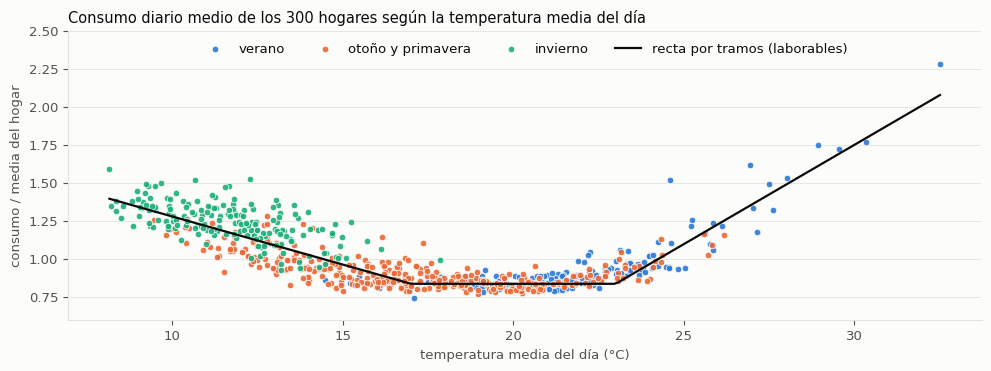

In [29]:
WEATHER_COLUMNS = {"temperature_2m": "temperatura", "relative_humidity_2m": "humedad", "precipitation": "lluvia",
                   "cloud_cover": "nubosidad", "shortwave_radiation": "radiación", "wind_speed_10m_ms": "viento"}
weather_hourly = pd.read_parquet(data_path, columns=["timestamp_utc", *WEATHER_COLUMNS], filters=[("customer", "==", 1)])
weather_hourly = (weather_hourly.loc[weather_hourly["timestamp_utc"].between(hour_calendar["timestamp_utc"].min(),
                                                                             hour_calendar["timestamp_utc"].max())]
                  .rename(columns=WEATHER_COLUMNS).sort_values("timestamp_utc", ignore_index=True))
if not weather_hourly["timestamp_utc"].equals(hour_calendar["timestamp_utc"]):
    raise ValueError("Las horas de ERA5 no coinciden con las de los hogares")
weather_hourly["fecha_local"] = hour_calendar["fecha_local"]
day_weather = weather_hourly.groupby("fecha_local").agg(
    temp_media=("temperatura", "mean"), temp_max=("temperatura", "max"), temp_min=("temperatura", "min"),
    humedad=("humedad", "mean"), nubosidad=("nubosidad", "mean"), lluvia=("lluvia", "sum"),
    radiación=("radiación", "mean"), viento=("viento", "mean"),
).loc[day_matrix.columns]

TEMP_BINS = [0, 10, 15, 20, 25, 35]
TEMP_LABELS = ["menos de 10 °C", "10-15 °C", "15-20 °C", "20-25 °C", "25 °C o más"]
print("Días según la temperatura media:")
display(pd.cut(day_weather["temp_media"], TEMP_BINS, right=False, labels=TEMP_LABELS)
        .value_counts(sort=False).to_frame("días").T)
print("Días con máxima de 30 °C o más:", int(day_weather["temp_max"].ge(30).sum()),
      "| de 35 °C o más:", int(day_weather["temp_max"].ge(35).sum()),
      f"| temperatura más alta de los dos años: {day_weather['temp_max'].max():.1f} °C")

mean_day_rel = day_matrix.div(day_matrix.mean(axis=1), axis=0).mean().to_numpy()
weekend = day_types["tipo_dia"].eq("fin de semana o festivo").to_numpy()


def hinge_fit(temp, cold, hot):
    """Recta por tramos del consumo diario medio: coeficientes y R²."""
    X = np.column_stack([np.ones(len(temp)), weekend, np.maximum(cold - temp, 0), np.maximum(temp - hot, 0)])
    coef = np.linalg.lstsq(X, mean_day_rel, rcond=None)[0]
    residual = mean_day_rel - X @ coef
    return coef, 1 - residual.var() / mean_day_rel.var()


fits = {}
for column, label in [("temp_media", "temperatura media"), ("temp_max", "máxima"), ("temp_min", "mínima")]:
    temp = day_weather[column].to_numpy()
    grid = [(cold, hot) for cold in np.arange(8, 30, 0.5) for hot in np.arange(cold, 34, 0.5)]
    cold, hot = max(grid, key=lambda bases: hinge_fit(temp, *bases)[1])
    coef, r2 = hinge_fit(temp, cold, hot)
    fits[label] = {"tramo plano (°C)": f"{cold:g} a {hot:g}", "R²": round(r2, 3),
                   "frío (% por °C)": round(100 * coef[2], 1), "calor (% por °C)": round(100 * coef[3], 1),
                   "fin de semana o festivo (%)": round(100 * coef[1], 1)}
    if column == "temp_media":
        COLD_BASE, HOT_BASE, hinge_coef = cold, hot, coef
print("Recta por tramos que mejor se ajusta con cada medida de la temperatura del día:")
display(pd.DataFrame(fits).T)

SEASON_GROUPS = {"verano": ("verano", BLUE), "otoño": ("otoño y primavera", ORANGE),
                 "primavera": ("otoño y primavera", ORANGE), "invierno": ("invierno", AQUA)}
season_group = day_types["estacion"].astype(str).map(lambda s: SEASON_GROUPS[s][0]).to_numpy()
fig, ax = plt.subplots(figsize=(10, 3.8))
for group, color in [("verano", BLUE), ("otoño y primavera", ORANGE), ("invierno", AQUA)]:
    chosen = season_group == group
    ax.scatter(day_weather["temp_media"].to_numpy()[chosen], mean_day_rel[chosen], s=22, color=color,
               edgecolor=SURFACE, linewidth=0.6, alpha=0.9, label=group)
line_temp = np.linspace(day_weather["temp_media"].min(), day_weather["temp_media"].max(), 200)
line = hinge_coef[0] + hinge_coef[2] * np.maximum(COLD_BASE - line_temp, 0) + hinge_coef[3] * np.maximum(line_temp - HOT_BASE, 0)
ax.plot(line_temp, line, color=TEXT, linewidth=1.6, label="recta por tramos (laborables)")
ax.set_xlabel("temperatura media del día (°C)")
ax.set_ylabel("consumo / media del hogar")
ax.set_title("Consumo diario medio de los 300 hogares según la temperatura media del día", loc="left")
ax.legend(loc="upper center", ncols=4)
ax.set_ylim(0.6, 2.5)
fig.tight_layout()
plt.show()

**Resultado.** El consumo diario forma una U con la temperatura. Es mínimo y casi plano cuando la temperatura media del día está entre 17 y 23 °C. Por debajo sube un 6,3 % de la media del hogar por cada grado, y por encima, un 13,1 %, el doble. La recta por tramos explica el 80 % de la variación del consumo medio de un día a otro. La temperatura media del día se ajusta mejor que la máxima (74 %, con el tramo plano entre 21 y 29,5 °C) y mucho mejor que la mínima (47 %).

Hay que tener en cuenta dos cosas:

- **El lado frío mezcla la temperatura con la época del año.** Los días fríos son sobre todo de invierno, que también tienen menos horas de luz, y en invierno el `CL` consume el doble (sección 3.3). La pendiente del frío recoge todo eso. La sección 5.2 separa lo que corresponde al tiempo de cada día.
- **El lado cálido tiene pocos días.** Solo 22 días tienen una media de 25 °C o más, y 5 una máxima de 35 °C o más; la más alta de los dos años es 40,6 °C. Son los días de más consumo (el más caluroso, con 32,5 °C de media, llega a 2,3 veces la media del hogar), y su relación con la temperatura se apoya en muy pocas observaciones.

### 5.2 Lo que añade la temperatura al calendario

El frío y la época del año van juntos: los días fríos son los de invierno, que también son los más cortos. El ciclo anual ya lo recoge el calendario (sección 3.3). Lo que puede añadir el tiempo es la diferencia entre un día y lo normal en su época, por ejemplo un día de invierno más frío de lo habitual o un día de verano más caluroso.

Se mide de dos formas:

- **Día a día.** El consumo de cada hogar respecto a su media en el mismo mes y tipo de día, promediado entre hogares, frente a la diferencia entre la temperatura media del día y la media de ese mes.
- **Hogar por hogar.** Qué parte de la desviación diaria de la sección 4.3 (respecto a la estación y el tipo de día) explica la temperatura. Se usan los grados por debajo y por encima del tramo plano de la sección 5.1, también como desviación respecto a su media en la misma estación y tipo de día, y se prueba a añadir los de los días anteriores. Después se repite la autocorrelación de la sección 4.3 con lo que queda sin explicar.

Desviación media del consumo (%) según la diferencia entre la temperatura del día y la media del mes (°C).
Solo tramos con 5 días o más:


tramo,−4 o menos,−4 a −2,−2 a −1,−1 a 0,0 a 1,1 a 2,2 a 4,más de 4
estación,,,,,,,,
verano,-12.2,-7.4,-7.7,-4.1,-2.1,2.4,15.3,39.9
otoño,NaN,3.0,1.2,1.1,-2.0,-2.4,-2.3,NaN
invierno,NaN,5.3,4.1,1.8,-1.1,-3.5,-5.9,NaN
primavera,4.7,3.9,0.1,-0.2,-3.5,-3.5,-1.9,4.1


Días de cada tramo:


tramo,−4 o menos,−4 a −2,−2 a −1,−1 a 0,0 a 1,1 a 2,2 a 4,más de 4
estación,,,,,,,,
verano,7,26,20,41,37,24,17,9
otoño,1,25,21,51,38,18,29,1
invierno,0,26,27,36,42,31,17,4
primavera,9,32,29,29,20,20,33,10


Pendiente (% por °C) y correlación entre las dos diferencias, por estación:


estación,verano,otoño,invierno,primavera
pendiente,4.77,-0.81,-2.40,-0.57
correlación,0.75,-0.19,-0.57,-0.20



Parte de la desviación diaria de cada hogar (sección 4.3) que explica la temperatura (R²), entre los 300 hogares:


,p10,mediana,p90
temperatura del día,0.018,0.141,0.392
del día y del anterior,0.021,0.155,0.408
del día y de los dos anteriores,0.023,0.163,0.411


Autocorrelación en algunos retardos (días); mediana de los hogares en las dos primeras filas:


,1,2,7,14
desviación de la sección 4.3,0.55,0.41,0.22,0.16
lo que no explica la temperatura del día y del anterior,0.47,0.34,0.20,0.13
temperatura media respecto a su estación y tipo de día,0.79,0.61,0.35,0.31


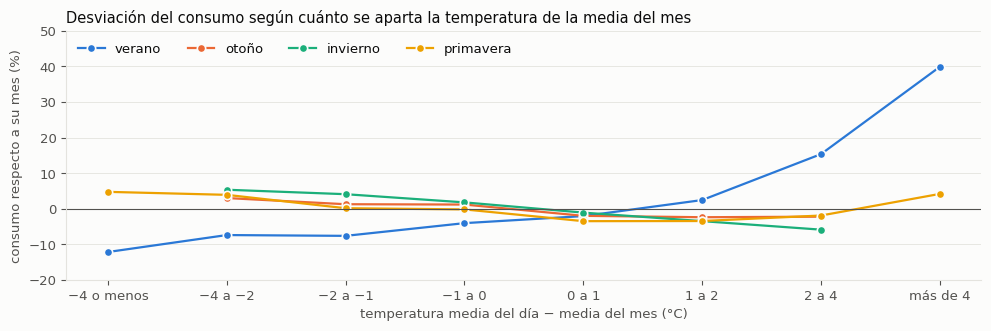

In [30]:
month_key = day_matrix.columns.to_period("M")
month_group = (month_key.astype(str) + " / " + day_types["tipo_dia"].astype(str)).to_numpy()
day_vs_month = (day_matrix / day_matrix.T.groupby(month_group).transform("mean").T - 1).replace([np.inf, -np.inf], np.nan)
anomaly = pd.DataFrame({
    "consumo": 100 * day_vs_month.mean().to_numpy(),
    "temperatura": (day_weather["temp_media"] - day_weather["temp_media"].groupby(month_key).transform("mean")).to_numpy(),
    "estación": day_types["estacion"].array,
}, index=day_matrix.columns)
ANOMALY_BINS = [-10, -4, -2, -1, 0, 1, 2, 4, 10]
ANOMALY_LABELS = ["−4 o menos", "−4 a −2", "−2 a −1", "−1 a 0", "0 a 1", "1 a 2", "2 a 4", "más de 4"]
anomaly["tramo"] = pd.cut(anomaly["temperatura"], ANOMALY_BINS, labels=ANOMALY_LABELS)
binned = anomaly.groupby(["estación", "tramo"], observed=True)["consumo"].agg(["mean", "size"])
binned_mean = binned["mean"].where(binned["size"].ge(5)).unstack()
print("Desviación media del consumo (%) según la diferencia entre la temperatura del día y la media del mes (°C).")
print("Solo tramos con 5 días o más:")
display(binned_mean.round(1))
print("Días de cada tramo:")
display(binned["size"].unstack().fillna(0).astype(int))
print("Pendiente (% por °C) y correlación entre las dos diferencias, por estación:")
display(anomaly.groupby("estación", observed=True)[["temperatura", "consumo"]].apply(lambda g: pd.Series({
    "pendiente": np.polyfit(g["temperatura"], g["consumo"], 1)[0], "correlación": g["temperatura"].corr(g["consumo"]),
})).round(2).T)

temp = day_weather["temp_media"].to_numpy()
cold_degrees = np.maximum(COLD_BASE - temp, 0)
hot_degrees = np.maximum(temp - HOT_BASE, 0)
valid_days = np.arange(len(temp)) >= 2


def calendar_residual(values):
    """Diferencia de una serie diaria respecto a su media en la misma estación y tipo de día."""
    values = pd.Series(np.asarray(values, dtype=float))
    return (values - values.groupby(day_group).transform("mean")).to_numpy()


def previous(values, days):
    return np.concatenate([np.full(days, np.nan), values[:-days]])


deviation = day_dev.to_numpy()[:, valid_days]


def explain(inputs):
    """Ajusta la desviación diaria de cada hogar con las entradas dadas: coeficientes, residuo y R²."""
    X = np.column_stack([np.ones(valid_days.sum())] + [calendar_residual(x)[valid_days] for x in inputs])
    coef = np.linalg.lstsq(X, deviation.T, rcond=None)[0]
    residual = deviation - (X @ coef).T
    return coef, residual, 1 - residual.var(axis=1) / deviation.var(axis=1)


TEMPERATURE_INPUTS = {
    "temperatura del día": [cold_degrees, hot_degrees],
    "del día y del anterior": [cold_degrees, hot_degrees, previous(cold_degrees, 1), previous(hot_degrees, 1)],
    "del día y de los dos anteriores": [cold_degrees, hot_degrees, previous(cold_degrees, 1), previous(hot_degrees, 1),
                                        previous(cold_degrees, 2), previous(hot_degrees, 2)],
}
explained = {name: explain(inputs) for name, inputs in TEMPERATURE_INPUTS.items()}
print("\nParte de la desviación diaria de cada hogar (sección 4.3) que explica la temperatura (R²), entre los 300 hogares:")
display(spread(np.array([r2 for _, _, r2 in explained.values()]), list(explained)).T.round(3))

ACF_DAYS = [1, 2, 7, 14]
acf_rows = {"desviación de la sección 4.3": np.median(autocorrelation(deviation, ACF_DAYS), axis=1),
            "lo que no explica la temperatura del día y del anterior":
                np.median(autocorrelation(explained["del día y del anterior"][1], ACF_DAYS), axis=1)}
temp_anomaly = pd.Series(calendar_residual(temp))
acf_rows["temperatura media respecto a su estación y tipo de día"] = [temp_anomaly.autocorr(lag) for lag in ACF_DAYS]
print("Autocorrelación en algunos retardos (días); mediana de los hogares en las dos primeras filas:")
display(pd.DataFrame(acf_rows, index=ACF_DAYS).T.round(2))

fig, ax = plt.subplots(figsize=(10, 3.4))
for season, color in zip(binned_mean.index, [BLUE, ORANGE, AQUA, YELLOW]):
    values = binned_mean.loc[season].reindex(ANOMALY_LABELS).to_numpy()
    ax.plot(range(len(ANOMALY_LABELS)), values, color=color, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=season)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_xticks(range(len(ANOMALY_LABELS)))
ax.set_xticklabels(ANOMALY_LABELS)
ax.set_xlabel("temperatura media del día − media del mes (°C)")
ax.set_ylabel("consumo respecto a su mes (%)")
ax.set_title("Desviación del consumo según cuánto se aparta la temperatura de la media del mes", loc="left")
ax.legend(loc="upper left", ncols=4)
ax.set_ylim(-20, 50)
fig.tight_layout()
plt.show()

**Resultado.** Una vez descontado el mes, la temperatura de cada día sigue importando, pero de forma distinta según la estación:

- **Verano.** Es donde más se nota, y el efecto crece deprisa con el calor. Respecto a lo normal en su mes, los días de 1 a 2 °C más calurosos consumen un 2 % más; los de 2 a 4 °C, un 15 %, y los de más de 4 °C, un 40 %. Los días más frescos de lo normal consumen hasta un 12 % menos. La correlación entre las dos diferencias es de 0,75.
- **Invierno.** Un día más frío de lo normal consume un 2,4 % más por grado (correlación de −0,57). Es menos de la mitad de la pendiente de 6,3 % de la sección 5.1: el resto del aumento del consumo en los días fríos va con la época del año, y eso ya lo recoge el calendario.
- **Otoño y primavera.** El efecto es pequeño (−0,8 y −0,6 % por grado). En primavera, que va de septiembre a noviembre, consumen algo más tanto los días más fríos de lo normal como los mucho más calurosos.

Hogar por hogar, la temperatura del día explica una mediana del 14 % de la desviación diaria de la sección 4.3, con mucha diferencia entre hogares: del 2 % en el percentil 10 al 39 % en el 90. Añadir la temperatura del día anterior sube la mediana al 15,5 %, y la de los dos días anteriores, al 16,3 %. El consumo responde sobre todo al tiempo del mismo día.

Lo que la temperatura no explica es casi tan persistente como la desviación completa. Su autocorrelación con el día anterior baja solo de 0,55 a 0,47, y a una semana, de 0,22 a 0,20. La temperatura sí es persistente (0,79 de un día al siguiente), pero explica poco de la desviación. Por tanto, la persistencia de la sección 4.3 se debe sobre todo a otras causas, seguramente cambios en el propio hogar como la ocupación o las rutinas, y los retardos del consumo y la temperatura aportan información distinta.

### 5.3 Horas del día

La temperatura no cambia el consumo igual a todas las horas. Se comparan los perfiles horarios de los laborables según la temperatura del día: en verano, según la máxima, que marca el calor de la tarde; en invierno, según la media. Después se mira, ya a escala horaria, si la desviación de la sección 4.1 sigue a la temperatura de la misma hora o a la de horas anteriores. La temperatura de ERA5 es instantánea: el valor de cada marca corresponde al final del intervalo de consumo.

Laborables de verano, días de cada grupo: {'hasta 25 °C': 63, '25-30 °C': 43, '30-35 °C': 12, 'más de 35 °C': 3}
Perfil de cada grupo / perfil del grupo «hasta 25 °C», por hora local:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
temp_max,,,,,,,,,,,,,,,,,,,,,,,,
25-30 °C,1.00,0.96,0.95,1.01,1.02,1.02,0.98,0.95,0.97,0.98,1.00,1.03,1.06,1.12,1.15,1.18,1.19,1.14,1.10,1.08,1.07,1.08,1.06,1.01
30-35 °C,1.12,1.04,1.05,1.18,1.18,1.13,1.02,1.00,1.08,1.13,1.23,1.41,1.59,1.86,2.00,2.10,2.11,1.88,1.74,1.68,1.63,1.62,1.46,1.25
más de 35 °C,1.18,1.04,1.09,1.31,1.25,1.26,1.16,1.14,1.19,1.21,1.46,1.76,2.16,2.61,2.91,3.20,3.32,2.94,2.65,2.50,2.29,2.21,1.82,1.51


Laborables de invierno, días de cada grupo: {'más de 14 °C': 14, '12-14 °C': 50, '10-12 °C': 38, 'hasta 10 °C': 25}
Perfil de cada grupo / perfil del grupo «más de 14 °C», por hora local:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
temp_media,,,,,,,,,,,,,,,,,,,,,,,,
12-14 °C,1.01,1.00,1.02,1.00,1.00,1.03,1.09,1.11,1.10,1.06,1.04,1.06,1.04,1.04,1.05,1.10,1.12,1.14,1.14,1.16,1.15,1.14,1.12,1.06
10-12 °C,1.06,1.07,1.08,1.06,1.06,1.10,1.15,1.22,1.25,1.19,1.14,1.16,1.14,1.15,1.18,1.26,1.27,1.30,1.27,1.29,1.28,1.26,1.19,1.11
hasta 10 °C,1.05,1.06,1.09,1.09,1.08,1.13,1.22,1.28,1.33,1.25,1.21,1.18,1.15,1.15,1.17,1.22,1.29,1.37,1.36,1.40,1.37,1.33,1.25,1.16


Correlación entre la desviación horaria del consumo y la de la temperatura (mediana de los hogares):


,misma hora,1 h antes,2 h antes,3 h antes,6 h antes,12 h antes,24 h antes,máxima del día
"verano, de 12:00 a 22:00",0.265,0.275,0.279,0.282,0.269,0.211,0.214,0.277
"invierno, de 6:00 a 9:00 y de 16:00 a 22:00",-0.094,-0.103,-0.103,-0.101,-0.110,-0.061,-0.081,-0.114


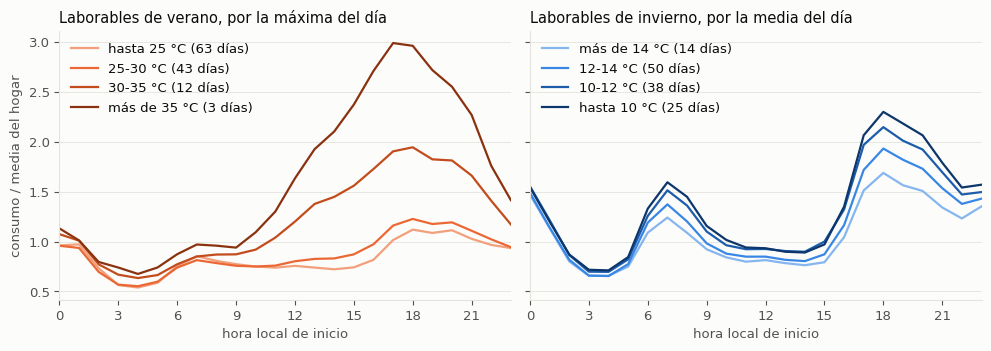

In [31]:
weekday_hourly = (train.loc[train["tipo_dia"].eq("laborable"), ["fecha_local", "hora_local", "estacion", "consumo_rel"]]
                  .join(day_weather[["temp_media", "temp_max"]], on="fecha_local", how="inner"))
# Grupos ordenados del día más templado al más extremo
PROFILE_GROUPS = {
    "verano": ("temp_max", [0, 25, 30, 35, 45], ["hasta 25 °C", "25-30 °C", "30-35 °C", "más de 35 °C"], False),
    "invierno": ("temp_media", [0, 10, 12, 14, 25], ["hasta 10 °C", "10-12 °C", "12-14 °C", "más de 14 °C"], True),
}
weather_profiles = {}
for season, (column, edges, labels, coldest_first) in PROFILE_GROUPS.items():
    rows = weekday_hourly.loc[weekday_hourly["estacion"].eq(season)]
    group = pd.cut(rows[column], edges, labels=labels)
    labels = labels[::-1] if coldest_first else labels
    profiles = rows.groupby([group, "hora_local"], observed=True)["consumo_rel"].mean().unstack().reindex(labels)
    day_count = rows.groupby(group, observed=True)["fecha_local"].nunique().reindex(labels)
    weather_profiles[season] = (profiles, day_count)
    print(f"Laborables de {season}, días de cada grupo:", day_count.to_dict())
    print(f"Perfil de cada grupo / perfil del grupo «{labels[0]}», por hora local:")
    display((profiles.iloc[1:] / profiles.iloc[0]).round(2))
del weekday_hourly

hour_of_day = hour_calendar["hora_local"].to_numpy()
hour_season = train["estacion"].astype(str).to_numpy()[order[:n_hours]]
hour_group = hour_season + " / " + train["tipo_dia"].astype(str).to_numpy()[order[:n_hours]]
hour_temp = weather_hourly["temperatura"]
hour_temp_dev = (hour_temp - hour_temp.groupby([hour_group, hour_of_day]).transform("mean")).to_numpy()
day_max = hour_calendar["fecha_local"].map(day_weather["temp_max"])
day_max_dev = (day_max - day_max.groupby(hour_group).transform("mean")).to_numpy()


def median_correlation(values, columns, lag=0):
    """Mediana entre hogares de la correlación entre la desviación horaria (sección 4.1) en columns y values lag horas antes."""
    x = values[columns - lag]
    x = (x - x.mean()) / x.std()
    dev = hourly_dev[:, columns]
    z = (dev - dev.mean(axis=1, keepdims=True)) / dev.std(axis=1, keepdims=True)
    return float(np.median((z * x).mean(axis=1)))


HOUR_TEMP_LAGS = [0, 1, 2, 3, 6, 12, 24]
correlations = {}
for season, label, hours in [("verano", "verano, de 12:00 a 22:00", range(12, 23)),
                             ("invierno", "invierno, de 6:00 a 9:00 y de 16:00 a 22:00", [6, 7, 8, 9, *range(16, 23)])]:
    columns = np.where((hour_season == season) & np.isin(hour_of_day, hours) & np.isfinite(day_max_dev))[0]
    columns = columns[columns >= 24]
    row = {f"{lag} h antes" if lag else "misma hora": median_correlation(hour_temp_dev, columns, lag)
           for lag in HOUR_TEMP_LAGS}
    row["máxima del día"] = median_correlation(day_max_dev, columns)
    correlations[label] = row
print("Correlación entre la desviación horaria del consumo y la de la temperatura (mediana de los hogares):")
display(pd.DataFrame(correlations).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
RAMPS = {"verano": ["#f2a07c", "#eb6834", "#c24c1c", "#8a3210"], "invierno": ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]}
for ax, (season, (profiles, day_count)) in zip(axes, weather_profiles.items()):
    for (label, profile), color in zip(profiles.iterrows(), RAMPS[season]):
        ax.plot(profile.index, profile.to_numpy(), color=color, label=f"{label} ({day_count[label]} días)")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_xlabel("hora local de inicio")
    ax.legend(loc="upper left")
axes[0].set_ylabel("consumo / media del hogar")
axes[0].set_title("Laborables de verano, por la máxima del día", loc="left")
axes[1].set_title("Laborables de invierno, por la media del día", loc="left")
fig.tight_layout()
plt.show()

**Resultado.** El calor y el frío cambian horas distintas del día:

- **Calor.** En los laborables de verano con máxima de 30 a 35 °C, el consumo empieza a subir a media mañana y se duplica entre las 14:00 y las 16:00, comparado con los días de hasta 25 °C. En los 3 días de más de 35 °C llega a 3,2 veces a las 15:00 y a 3,3 a las 16:00. De madrugada también sube, hasta un 18 % con 30 a 35 °C y un 31 % con más de 35 °C. Con 25 a 30 °C el aumento es pequeño, como mucho un 19 % a las 16:00.
- **Frío.** En los laborables de invierno de hasta 10 °C de media, el consumo sube sobre todo en las dos puntas del día, comparado con los de más de 14 °C: un 28 a 33 % a las 07:00 y las 08:00, y un 36 a 40 % de las 17:00 a las 20:00. De madrugada apenas cambia (de un 5 a un 9 %).

A escala horaria, la hora exacta de la temperatura importa poco. En las tardes de verano, la desviación del consumo se correlaciona casi igual con la temperatura de la misma hora (0,27), con la de 2 o 3 horas antes (0,28) y con la máxima del día (0,28). Incluso con la de 24 horas antes la correlación es de 0,21, porque los días de calor suelen venir seguidos. En invierno la correlación es débil, en torno a −0,1, con cualquier retardo. Lo que cuenta es lo caluroso o lo frío que es el día.

### 5.4 Diferencias entre hogares

El ajuste de la sección 5.2 con la temperatura del día da a cada hogar dos coeficientes: cuánto sube su consumo diario por cada grado por debajo del tramo plano y por cada grado por encima. Se expresan en % del consumo medio diario del hogar. En los hogares con carga controlada se repite el cálculo por separado para el `GC` y el `CL`.

Aumento del consumo diario por grado (% de la media del hogar), entre los 300 hogares:


,count,mean,std,min,10%,25%,50%,75%,90%,max
frío,300.0,4.2,4.1,-10.2,-0.5,1.3,3.6,6.6,9.6,17.3
calor,300.0,13.0,13.5,-4.2,-1.1,2.7,10.0,19.1,29.9,76.5


Hogares con menos de 2 % por grado de calor: 65 | con más de 20 %: 71 | con menos de 1 % por grado de frío: 70
Correlación de Spearman entre las dos sensibilidades: 0.00

Mediana según el grupo de hogares:


,frío,calor
con CL,3.7,9.1
sin CL,3.5,11.4
más consumo en verano que en invierno (sección 3.3),0.1,16.4
más consumo en invierno,4.5,8.1


Hogares con CL (136): aumento por grado de cada parte, en % de su propia media (mediana):


,frío,calor
GC,3.1,13.7
CL,5.3,-4.6


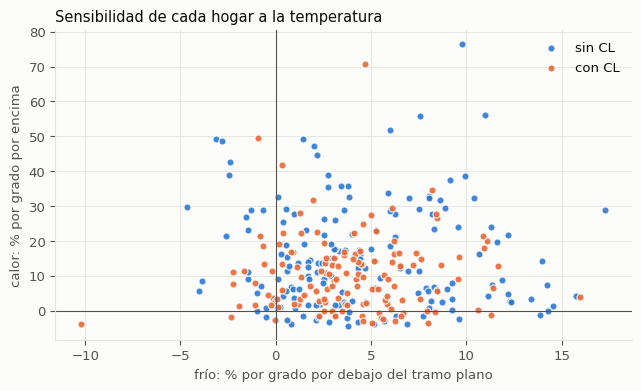

In [32]:
temp_coef = explained["temperatura del día"][0]
mean_daily_kwh = day_matrix.mean(axis=1).to_numpy()
sensitivity = pd.DataFrame({"frío": 100 * temp_coef[1] / mean_daily_kwh, "calor": 100 * temp_coef[2] / mean_daily_kwh},
                           index=day_matrix.index)
print("Aumento del consumo diario por grado (% de la media del hogar), entre los 300 hogares:")
display(sensitivity.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).T)
print("Hogares con menos de 2 % por grado de calor:", int(sensitivity["calor"].lt(2).sum()),
      "| con más de 20 %:", int(sensitivity["calor"].gt(20).sum()),
      "| con menos de 1 % por grado de frío:", int(sensitivity["frío"].lt(1).sum()))
print(f"Correlación de Spearman entre las dos sensibilidades: {sensitivity['frío'].corr(sensitivity['calor'], method='spearman'):.2f}")
print("\nMediana según el grupo de hogares:")
display(pd.DataFrame({
    "con CL": sensitivity.loc[customers["has_cl"]].median(),
    "sin CL": sensitivity.loc[~customers["has_cl"]].median(),
    "más consumo en verano que en invierno (sección 3.3)": sensitivity.loc[summer_peak].median(),
    "más consumo en invierno": sensitivity.loc[~summer_peak].median(),
}).T.round(1))

cl_customers = customers.index[customers["has_cl"]]
component_rows = {}
for column, label in [("gc_kwh", "GC"), ("cl_kwh", "CL")]:
    component = (train.loc[train["has_cl"]].groupby(["customer", "fecha_local"])[column].sum()
                 .unstack("fecha_local").loc[cl_customers, day_matrix.columns])
    component_dev = (component - component.T.groupby(day_group).transform("mean").T).to_numpy()[:, valid_days]
    X = np.column_stack([np.ones(valid_days.sum()), calendar_residual(cold_degrees)[valid_days],
                         calendar_residual(hot_degrees)[valid_days]])
    coef = np.linalg.lstsq(X, component_dev.T, rcond=None)[0]
    component_rows[label] = {"frío": np.median(100 * coef[1] / component.mean(axis=1).to_numpy()),
                             "calor": np.median(100 * coef[2] / component.mean(axis=1).to_numpy())}
print(f"Hogares con CL ({len(cl_customers)}): aumento por grado de cada parte, en % de su propia media (mediana):")
display(pd.DataFrame(component_rows).T.round(1))

fig, ax = plt.subplots(figsize=(6.5, 4))
for flag, color, label in [(False, BLUE, "sin CL"), (True, ORANGE, "con CL")]:
    chosen = customers["has_cl"].eq(flag).reindex(sensitivity.index).to_numpy()
    ax.scatter(sensitivity.loc[chosen, "frío"], sensitivity.loc[chosen, "calor"], s=26, color=color,
               edgecolor=SURFACE, linewidth=0.8, alpha=0.9, label=label)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.grid(axis="x")
ax.set_xlabel("frío: % por grado por debajo del tramo plano")
ax.set_ylabel("calor: % por grado por encima")
ax.set_title("Sensibilidad de cada hogar a la temperatura", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Resultado.** Los hogares responden a la temperatura de forma muy distinta, sobre todo al calor:

- **Calor.** La mediana es de un 10 % más de consumo por cada grado por encima de 23 °C de media, pero 65 hogares apenas reaccionan (menos de un 2 % por grado) y 71 suben más de un 20 %. Seguramente es la diferencia entre tener aire acondicionado o no, algo que los datos no indican.
- **Frío.** La mediana es de un 3,6 % por grado por debajo de 17 °C, y 70 hogares suben menos de un 1 %.
- **Las dos sensibilidades no van juntas.** Su correlación es nula (0,00): cómo reacciona un hogar al calor no dice nada de cómo reacciona al frío.

Los 55 hogares que consumen más en verano que en invierno (sección 3.3) casi no reaccionan al frío (mediana de 0,1 % por grado) y reaccionan más que el resto al calor (16,4 %). Tener carga controlada apenas cambia la sensibilidad del consumo total, pero en esos hogares el `GC` y el `CL` responden al revés. El `GC` sube con el calor (13,7 % por grado) y algo con el frío (3,1 %). El `CL` sube con el frío (5,3 %) y baja con el calor (−4,6 %), lo esperable en un calentador de agua, que gasta más cuanto más fría entra el agua.

Como hay pocos días de calor (sección 5.1), la sensibilidad al calor de cada hogar se estima con poca precisión.

### 5.5 Humedad y otras variables

El Plan prevé usar la humedad además de la temperatura. Se mira si la humedad y las demás variables de ERA5 (nubosidad, lluvia, radiación y viento) se relacionan con lo que la temperatura no explica. Para cada hogar se toma lo que queda tras el ajuste con la temperatura del día y del anterior (sección 5.2) y se calcula su correlación con cada variable diaria, también como desviación respecto a su media en la misma estación y tipo de día. Se hace por estaciones, porque el efecto puede cambiar entre el verano y el invierno.

In [33]:
OTHER_WEATHER = ["humedad", "nubosidad", "lluvia", "radiación", "viento"]
base_residual = explained["del día y del anterior"][1]
day_season = day_types["estacion"].to_numpy()[valid_days]


def median_day_correlation(values, columns):
    x = (values[columns] - values[columns].mean()) / values[columns].std()
    dev = base_residual[:, columns]
    z = (dev - dev.mean(axis=1, keepdims=True)) / dev.std(axis=1, keepdims=True)
    return float(np.median((z * x).mean(axis=1)))


other_dev = {name: calendar_residual(day_weather[name])[valid_days] for name in OTHER_WEATHER}
print("Correlación de lo que no explica la temperatura con cada variable (mediana de los hogares):")
display(pd.DataFrame({
    season: {name: median_day_correlation(values, day_season == season) for name, values in other_dev.items()}
    for season in ["verano", "otoño", "invierno", "primavera"]
}).round(2))

hot_days = (day_season == "verano") & (temp[valid_days] >= 22)
print(f"Días de verano con temperatura media de 22 °C o más: {int(hot_days.sum())}. "
      f"Correlación con la humedad: {median_day_correlation(day_weather['humedad'].to_numpy()[valid_days], hot_days):.2f}")
print("Correlación entre la humedad y la temperatura media del día en verano:",
      f"{day_weather.loc[day_types['estacion'].eq('verano').to_numpy(), ['humedad', 'temp_media']].corr().iloc[0, 1]:.2f}")

base_inputs = TEMPERATURE_INPUTS["del día y del anterior"]
extended = {
    "temperatura del día y del anterior": explained["del día y del anterior"][2],
    "+ humedad": explain(base_inputs + [day_weather["humedad"].to_numpy()])[2],
    "+ las cinco variables": explain(base_inputs + [day_weather[name].to_numpy() for name in OTHER_WEATHER])[2],
}
print("\nParte de la desviación diaria que se explica (R²), entre los 300 hogares:")
display(spread(np.array(list(extended.values())), list(extended)).T.round(3))

Correlación de lo que no explica la temperatura con cada variable (mediana de los hogares):


,verano,otoño,invierno,primavera
humedad,0.02,0.06,0.04,0.07
nubosidad,-0.03,0.09,0.12,0.07
lluvia,0.01,0.07,0.13,0.06
radiación,0.01,-0.11,-0.14,-0.10
viento,-0.00,0.10,0.11,0.04


Días de verano con temperatura media de 22 °C o más: 73. Correlación con la humedad: -0.03
Correlación entre la humedad y la temperatura media del día en verano: -0.18

Parte de la desviación diaria que se explica (R²), entre los 300 hogares:


,p10,mediana,p90
temperatura del día y del anterior,0.021,0.155,0.408
+ humedad,0.030,0.163,0.411
+ las cinco variables,0.050,0.187,0.440


**Resultado.** La humedad apenas añade nada a la temperatura. Su correlación con lo que la temperatura no explica está entre 0,02 y 0,07 en todas las estaciones. En los 73 días de verano con 22 °C de media o más, que es donde podría importar, es de −0,03. Añadida al ajuste, la parte explicada pasa del 15,5 % al 16,3 %. La humedad y la temperatura del día apenas están relacionadas en verano (−0,18), así que la falta de efecto no se debe a que la temperatura ya lo recoja. En un clima más cálido y húmedo el resultado podría ser distinto (G8).

Las demás variables tampoco cambian nada en verano. En el resto del año, los días nublados, lluviosos, ventosos y con menos radiación consumen algo más de lo que indica su temperatura, con correlaciones de 0,11 a 0,14 en invierno, seguramente por la iluminación y porque se pasa más tiempo en casa. Con las cinco variables, la parte explicada sube al 18,7 %. Con 726 días, cinco variables sin ninguna relación la subirían menos de un punto, así que la subida es real, aunque pequeña.

Este efecto va en la misma dirección que la generación: los días nublados de invierno, en que los paneles producen menos, el consumo es algo mayor. Es un motivo más para que el consumo y la generación salgan de los mismos escenarios meteorológicos en la simulación de Monte Carlo (G11).

## Resumen de hallazgos

| Aspecto | Resultado |
|---|---|
| Partición | El análisis usa 2010-2011 y 2011-2012: 300 hogares con 17.535 horas cada uno, sin huecos. 2012-2013 queda para el test |
| Calendario | Hora local de inicio del intervalo. 27 festivos, 18 en día laborable (el 28 de diciembre de 2010 se añade a mano). Los días de cambio de horario tienen 23 o 25 horas |
| Forma de la distribución | Cola larga: mediana 0,46 kWh, media 0,77, máximo 14,1. Asimetría 2,85, que baja a 1,41 con `log1p` |
| Ceros | 0,07 % de las horas, concentrados en pocos hogares con periodos de casa vacía |
| Valores muy bajos | 3,9 % de las horas por debajo de 0,1 kWh, muy concentrados: en algunos hogares superan la mitad de sus horas |
| Picos | El 1 % de las horas reúne el 7 % de la energía. Los picos más altos son de madrugada y se deben a la carga controlada |
| Media y mediana | Incluso dentro de cada hogar, estación, tipo de día y hora, la media es un 22 % mayor que la mediana (mediana de las combinaciones). Si se tomara la mediana, la energía total sería un 17,7 % menor |
| Nivel de los hogares | De 6,6 a 38,7 kWh/día. La carga controlada y la potencia FV apenas lo explican |
| Variabilidad | Coeficiente de variación horario de 1,02 y diario de 0,40. Los hogares que más consumen son algo más regulares |
| Forma del perfil | Dos formas dominantes: pico de tarde (hogares sin `CL`) y pico de madrugada (calentador de agua de los hogares con `CL`) |
| Periodos de casa vacía | Con el total diario por debajo del 20 % de la mediana: 76 rachas de 3 días o más en 37 hogares, algunas de más de tres meses. Diciembre concentra rachas los dos años; julio, solo en 2010. Ese criterio no capta las casas vacías con aparatos programados; la hora típica del día sí, pero los días marcados dependen mucho del umbral (de 1.458 a 4.315) |
| Cambios de nivel | La mayoría estables; 13 hogares cambian por un factor de 1,5 o más entre años. El hogar 146 es atípico en casi todo |
| Día de la semana | De lunes a viernes, mismo consumo y casi la misma forma; el viernes se separa algo. Sábado y domingo consumen un 4 y un 6 % más, sin el pico de las 07:00 y con más consumo a mediodía. En la mitad de los hogares la diferencia de nivel es menor del 5 % |
| Festivos y Navidad | Los festivos se consumen como un domingo, salvo el *Bank Holiday*, que se consume como un laborable. Del 23 de diciembre al 6 de enero los laborables se parecen a un fin de semana |
| Vacaciones escolares y calor | En las épocas de vacaciones escolares, los laborables recorren entre un tercio y la mitad del camino hacia la forma de un fin de semana (fechas no comprobadas). Los días de más de 30 °C también la acercan |
| Época del año | Máximo en invierno (julio, un 30 % sobre la media) y mínimo en primavera y otoño. El verano depende del calor del año. 55 hogares consumen más en verano que en invierno. En invierno el pico de la tarde es mucho mayor y aparece otro por la mañana |
| Hora local | El consumo general sigue el reloj: en los cambios de horario el perfil se mantiene en hora local, no en UTC. El `CL` es la excepción |
| Autocorrelación | 0,59 con la hora anterior, 0,52 con el día anterior y 0,44 con la semana anterior. El calendario explica un 33 % de la varianza horaria; lo que queda se correlaciona 0,50 con la hora anterior y 0,28 con el día anterior |
| Persistencia | Copiar el día anterior (error del 50 % del consumo medio) acierta más que copiar la semana anterior (54 %) en 259 hogares. La media de la misma hora en los 7 días anteriores (44 %) acierta más que las dos en 292 |
| Duración de las desviaciones | Las desviaciones de la energía diaria tienen una autocorrelación de 0,55 a un día y de 0,22 a una semana, y son casi 0 a partir de unas 6 semanas |
| Semanas y meses | Al pronosticar la energía de una semana, la semana reciente acierta más hasta los 43 días; después, la misma semana del año anterior (error del 24 %) |
| Carga controlada | Horario muy fijo (el 93 % del `CL` de cada día cae en sus 5 horas habituales) pero cantidad variable, y muchos días sin `CL` en verano. En 66 de los 136 hogares el temporizador sigue la hora estándar todo el año |
| Temperatura | El consumo diario forma una U: mínimo entre 17 y 23 °C de media; un 6,3 % más por grado de frío y un 13,1 % por grado de calor. Hay pocos días de calor: 22 con media de 25 °C o más y 5 con máxima de 35 °C o más (máximo de 40,6 °C) |
| Temperatura y calendario | Descontado el mes, el calor sigue pesando mucho en verano (un 40 % más con más de 4 °C sobre la media del mes) y el frío, menos (2,4 % por grado en invierno). La temperatura explica un 14 % de la desviación diaria de cada hogar (mediana), la de los días anteriores añade poco y la persistencia de las desviaciones apenas baja (de 0,55 a 0,47) |
| Horas del día | El calor sube la tarde (el doble de 14:00 a 16:00 con 30-35 °C de máxima, y más del triple con más de 35 °C); el frío, las dos puntas del día (un 30 % por la mañana y un 40 % por la tarde). La hora exacta de la temperatura importa poco |
| Sensibilidad de los hogares | Muy variable: 65 hogares apenas reaccionan al calor y 71 suben más de un 20 % por grado. Las sensibilidades al frío y al calor no se relacionan. El `CL` sube con el frío y baja con el calor |
| Humedad y otras variables | La humedad no añade nada. Fuera del verano, los días nublados, lluviosos y ventosos consumen algo más; con las cinco variables, la parte explicada pasa del 15,5 al 18,7 % |

## Preguntas abiertas

Este cuaderno no toma decisiones de modelado. Estas son las preguntas que dejan los hallazgos, para resolverlas más adelante:

1. **Métricas.** El Plan evalúa con MAE, MASE y sesgo. Los niveles de los hogares varían casi 6 veces (sección 2.1), así que un MAE calculado con todos los hogares juntos estará dominado por los que más consumen. ¿Se resume el error hogar por hogar, se usa el MASE, que escala el error de cada uno, o las dos cosas? Para el MASE, ¿se escala con la persistencia de 24 horas o con la de 168? La de 24 horas tiene menos error, así que da una escala algo más exigente (sección 4.2). El MAPE no está en el Plan, y los datos lo desaconsejan: en algunos hogares la mitad de las horas está por debajo de 0,1 kWh, y ahí el error porcentual se dispara (sección 1.2).
2. **Transformación.** `log1p` reduce la asimetría a la mitad. ¿Compensa, teniendo en cuenta que al deshacerla el modelo tiende a predecir la mediana? (secciones 1.1 y 1.5)
3. **Función de pérdida.** La media y la mediana se separan incluso conociendo el hogar y el calendario. ¿Se entrena para predecir la media (L2, Tweedie) o la mediana (L1)? Conviene decidirlo teniendo en cuenta dos cosas del Plan. El MAE premia predecir la mediana, pero la simulación de la batería suma las horas, y sumar medianas da un 17,7 % menos de energía que la real (sección 1.5). Un modelo con buen MAE podría subestimar el consumo nocturno y dar una autonomía mayor que la real. El sesgo, que el Plan ya incluye, permitiría detectarlo.
4. **Carga controlada.** Los picos más altos y el perfil de madrugada son del `CL`. Se enciende casi siempre a las mismas horas, pero su cantidad varía mucho, muchos hogares apenas lo usan en verano y, en casi la mitad, su temporizador sigue la hora estándar y no la local (sección 4.5). Además, responde al tiempo al revés que el `GC`: sube con el frío y baja con el calor (sección 5.4). ¿Se predice `demand_kwh` directamente o `GC` y `CL` por separado, como deja abierto G13 en `docs/data/gaps.md`? Si se predice junto, ¿hace falta una variable de hora estándar para que el modelo pueda situar el encendido del `CL`? (secciones 1.4, 2.4, 3.3, 4.5 y 5.4)
5. **Diferencias entre hogares.** Niveles que varían casi 6 veces, dos formas de perfil, respuestas opuestas a la estación (55 hogares consumen más en verano) y sensibilidades al calor que van de casi nada a más de un 20 % por grado. ¿Hay que normalizar por hogar? ¿Un modelo global, uno por grupo o uno por hogar? (secciones 2.1 a 2.4, 3.3 y 5.4)
6. **Periodos atípicos.** Casas vacías y cambios de nivel. ¿Con qué criterio y umbral se detectan las casas vacías? ¿Se excluyen del entrenamiento, de la evaluación o de ninguno? ¿Qué se hace con el hogar 146? (secciones 2.5 y 2.6)
7. **Calendario.** El *Bank Holiday* se consume como un laborable: ¿se quita de los festivos? Del 23 de diciembre al 6 de enero los laborables se parecen a un fin de semana: ¿se añade una marca para ese periodo? Las vacaciones escolares también parecen notarse, pero sus fechas de 2010 a 2012 no se han comprobado: ¿se buscan, o se deja que el modelo lo recoja con los retardos? ¿Bastan dos tipos de día o conviene separar sábado y domingo? (secciones 3.1 y 3.2)
8. **Referencias.** La persistencia de 24 horas acierta más que la de 168 horas en 259 hogares, y la media de la misma hora en los 7 días anteriores, más que las dos en 292. ¿Cuál se usa como persistencia estacional y cuál como media estacional? (sección 4.2)
9. **Retardos y horizontes.** Lo que el calendario no explica se correlaciona sobre todo con la hora anterior y con el mismo momento de los días anteriores, y deja de aportar hacia las 6 semanas. ¿Qué retardos usa LightGBM? ¿A partir de qué horizonte se pasa del modelo horario al de energía semanal? Los datos apuntan a algo entre 3 y 6 semanas (secciones 4.1, 4.3 y 4.4)
10. **Variables meteorológicas.** El consumo responde a la temperatura del día en forma de U, sobre todo en las tardes de calor; la temperatura de los días anteriores añade poco y la humedad, nada (secciones 5.1 a 5.5). ¿Qué medidas de la temperatura se dan a los modelos: la de cada hora, la media o la máxima del día, los grados por debajo y por encima de un tramo plano? ¿Se mantiene la humedad que prevé el Plan, aunque en Sídney no aporte, pensando en un clima tropical (G8)?
11. **Días de calor.** El calor es lo que más sube el consumo, y los días de calor son los que menos se repiten en los datos: 5 días de entrenamiento superan los 35 °C (sección 5.1). Además, `weather_exploration.ipynb` registra 44,8 °C el 18 de enero de 2013, en el año de test, por encima del máximo de entrenamiento (40,6 °C), y LightGBM no extrapola más allá de lo que vio al entrenar. ¿Cómo se tratan esos días? Como aquí se usa el tiempo observado (G9), el error del pronóstico meteorológico pesará sobre todo en esos días, que son los de más consumo. ¿Se evalúan aparte?